# Q6: Where is need larger than food shelf activity shows?

**MinneMUDAC 2026 · The Food Group · undergraduate division**

> *"Build a divergence measure for need and demand. Food shelf activity shows where people arrive. It does not show where people need help and do not get it. Create a new metric or measure that highlights the areas where need is likely larger than the activity data shows. Compare and contrast this measure of need against the three food shelf metrics. [...] Akin to Question 1, investigate various county characteristics that might help explain why there is disagreement."*

**Words (from the challenge glossary, used exactly this way below)**

| Term | Meaning here |
|---|---|
| **Need** | people who lack enough food, *including people not interacting with the system*. Measured with public hardship data (food insecurity, poverty, unemployment, housing cost burden...). |
| **Demand** | people actively seeking/receiving food assistance. Here: food shelf **visits**, **pounds**, **individuals** per 1,000 residents. |
| **Unmet need** | people needing food assistance who do not receive it (or not in full). |
| **Latent demand** | need that never becomes a request (awareness, stigma, eligibility uncertainty). |
| **Unmet demand** | a request the system can't fill (stockout, location, hours). |

**Plan**
1. Build a **need index** only from non-activity public data (sections 3-6).
2. Build a **demand index** from the three food shelf metrics, kept separate (section 7).
3. **Divergence** = need rank − demand rank, per metric and combined (sections 8-10).
4. Check it is **stable** (years, weights, components, data quality, cross-county use) (sections 11-12).
5. **Explain** divergence with access / network characteristics, as in Q1 (sections 13-14).
6. What would prove it wrong, save outputs, slide-ready summary (sections 15-18).

Data years: **2022-2024** only (the years with both Map the Meal Gap and food shelf data). No data dated August 2026 or later is used.

## 1. Imports and paths

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)

ROOT = Path.cwd().parent if (Path.cwd().parent / "Data").exists() and not (Path.cwd() / "Data").exists() else Path.cwd()
PROCESSED = ROOT / "Data" / "processed"
LOCAL = ROOT / "Data" / "local"            # git-ignored cache for public downloads (same as Q1)
OUT = ROOT / "outputs" / "q6"
OUT.mkdir(parents=True, exist_ok=True)
LOCAL.mkdir(parents=True, exist_ok=True)

YEARS = [2022, 2023, 2024]
METRICS = ["visits", "pounds", "individuals"]
NICE = {"visits": "Visits", "pounds": "Pounds", "individuals": "Individuals", "combined": "Combined"}
# Colorblind-checked categorical palette (same hues as the team's other charts)
COLOR = {"visits": "#2a78d6", "pounds": "#eb6834", "individuals": "#1baf7a", "combined": "#3d3d3a"}
UNDER, OVER, MID = "#e34948", "#2a78d6", "#f0efec"   # diverging: red = need above activity, blue = activity above need
DIV_CMAP = LinearSegmentedColormap.from_list("q6div", [OVER, MID, UNDER])
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10, "axes.titleweight": "bold"})
TOP_N = 15
print("Repo root:", ROOT)

Repo root: C:\Users\dinsa\OneDrive - UW-Madison\Documents\AA MINNEMUDAC\MINNEMUDAC_2026


## 2. Load the data

All joins use `fips` read as **text**. Census ACS files call it `county_geoid`, so we rename it.

In [2]:
read = lambda f, **k: pd.read_csv(PROCESSED / f, dtype={"fips": str, "county_geoid": str}, **k)
fs_month = read("foodshelf_county_month.csv", parse_dates=["month"])
mmg = read("mmg_mn_county_2022_2024.csv")
fac_y = read("county_factors_2022_2024.csv")
fac_s = read("county_factors_static.csv")
pov = read("poverty_2022_2024_clean.csv").rename(columns={"county_geoid": "fips"})
veh = read("vehicle_access_2022_2024_clean.csv").rename(columns={"county_geoid": "fips"})
rural = read("rural_share_2020_clean.csv")
q1 = read("q1_county_profiles.csv")

for name, d in [("fs_month", fs_month), ("mmg", mmg), ("factors yearly", fac_y), ("factors static", fac_s),
                ("poverty", pov), ("vehicles", veh), ("rural", rural), ("q1 profiles", q1)]:
    print(f"{name:15s} {d.shape}  counties={d['fips'].nunique()}")
assert fs_month["month"].max() < pd.Timestamp("2026-08-01"), "no August 2026+ data allowed"
COUNTY = dict(zip(mmg["fips"], mmg["county"]))

fs_month        (4785, 12)  counties=87
mmg             (261, 21)  counties=87
factors yearly  (261, 51)  counties=87
factors static  (87, 52)  counties=87
poverty         (261, 16)  counties=87
vehicles        (261, 9)  counties=87
rural           (87, 9)  counties=87
q1 profiles     (87, 42)  counties=87


## 3. The need index: what goes in, and what stays out

**Rule 1: need ≠ demand.** The need index uses **no** visits, pounds or individuals. Otherwise "need minus demand" would partly compare demand with itself.

**Rule 2: access barriers stay out of the need index.** Distance to a food shelf, sites per resident, grocery access, no-vehicle households, rurality, tribal land, broadband, limited English: these describe whether need can **turn into** demand, not how much need there is. We keep them aside and use them in section 13 to **explain** divergence. If they were inside the index, explaining divergence with them would be circular (the index would be high *because* a county is remote, and then we'd "discover" remoteness explains it).

**Candidate need indicators** (per-capita rates; hardship, eligibility, vulnerability):

| Indicator | Source | Yearly? |
|---|---|---|
| Food insecurity rate `fi_rate`, child FI rate | Feeding America Map the Meal Gap | yes |
| Poverty rate (SAIPE single-year; ACS 5-yr), child poverty, deep poverty (<50% FPL), below 185% FPL, below 150% FPL | Census SAIPE / ACS S1701 / CDC SVI | mostly |
| Unemployment rate (BLS; ACS) | BLS LAUS / SVI | BLS yes |
| Median household income (reversed) | Census SAIPE | yes |
| Low-income housing cost burden; severe housing cost burden | SVI (ACS) / County Health Rankings | no |
| Disability | SVI (ACS) | no |
| Single-parent households; children in single-parent households | SVI / CHR | no |
| Uninsured (all ages ACS; under 65 SAHIE) | SVI / CHR | no |
| No high-school diploma; children eligible for free/reduced lunch | SVI / CHR | no |
| FI above the SNAP income limit | MMG | yes |

Static (one-vintage) indicators are repeated in every year. ACS "years" are 5-year windows, so they move slowly.

In [3]:
mmg_cols = ["fi_rate", "child_fi_rate", "pct_fi_above_snap_threshold"]
yearly = (fac_y[["fips", "year", "pop_pep", "unemployment_rate", "saipe_poverty_rate", "saipe_child_poverty_rate", "median_hh_income"]]
          .merge(mmg[["fips", "year"] + mmg_cols], on=["fips", "year"], validate="one_to_one")
          .merge(pov[["fips", "year", "poverty_rate", "deep_poverty_rate", "below_185_rate"]], on=["fips", "year"], validate="one_to_one"))
yearly["income_reversed"] = -yearly["median_hh_income"]   # higher = more need
static_need = ["pct_below_150_poverty", "pct_unemployed_acs", "pct_housing_cost_burden_lowinc", "chr_pct_severe_housing_cost_burden",
               "pct_disability", "pct_single_parent_hh", "chr_pct_children_single_parent", "pct_uninsured", "chr_pct_uninsured_under65",
               "pct_no_hs_diploma", "chr_pct_children_frl_eligible"]
panel = yearly.merge(fac_s[["fips"] + static_need], on="fips", validate="many_to_one")
assert panel.shape[0] == 87 * 3 and not panel.duplicated(["fips", "year"]).any()

CANDIDATES = ["fi_rate", "child_fi_rate", "saipe_poverty_rate", "poverty_rate", "saipe_child_poverty_rate", "deep_poverty_rate",
              "below_185_rate", "pct_below_150_poverty", "unemployment_rate", "pct_unemployed_acs", "income_reversed",
              "pct_housing_cost_burden_lowinc", "chr_pct_severe_housing_cost_burden", "pct_disability", "pct_single_parent_hh",
              "chr_pct_children_single_parent", "pct_uninsured", "chr_pct_uninsured_under65", "pct_no_hs_diploma",
              "chr_pct_children_frl_eligible", "pct_fi_above_snap_threshold"]
print("Missing values among candidates:", int(panel[CANDIDATES].isna().sum().sum()))
cand_avg = panel.groupby("fips")[CANDIDATES].mean()   # 2022-2024 average, one row per county
cand_avg.describe().T[["mean", "min", "50%", "max"]].round(2)

Missing values among candidates: 0


,mean,min,50%,max
fi_rate,0.11,0.07,0.11,0.16
child_fi_rate,0.16,0.08,0.16,0.25
saipe_poverty_rate,10.15,4.60,10.20,17.90
poverty_rate,10.09,4.13,10.00,19.93
saipe_child_poverty_rate,11.59,3.77,11.27,24.27
deep_poverty_rate,4.42,2.20,4.47,10.33
below_185_rate,23.29,9.10,24.17,42.93
pct_below_150_poverty,17.76,6.80,18.20,36.00
unemployment_rate,3.24,2.00,2.97,6.83
pct_unemployed_acs,3.77,1.00,3.70,10.30


## 4. Redundancy screen: keep a small, explainable set

Many candidates measure the same thing (e.g. three poverty rates). Keeping all of them would let one idea (income poverty) dominate the index just because it was measured many times.

**Rule (fixed before looking at results):** need has several *dimensions* (food insecurity, poverty, income, jobs, housing, disability, family structure, health insurance). We take **at most one indicator per dimension**: walking down each dimension's preference list, the first indicator whose Spearman correlation with every indicator already kept is **≤ 0.80** is kept. Map the Meal Gap's food insecurity rate goes first (the challenge's own need measure).

Two candidates are excluded on **meaning**, not correlation:
- **FI above the SNAP limit** (`pct_fi_above_snap_threshold`): it says *which channel* food-insecure people can use (SNAP or not), not *how many* need help. It is almost a mirror image of the below-185% poverty rate (ρ ≈ −0.9), so including it would subtract poverty. It is used as an **explanatory** variable in section 13 (as in Q1).
- **Free/reduced lunch eligibility**: the glossary warns FRPL is becoming unreliable as schools move to universal meals (CEP).
- **No high-school diploma**: a risk factor for low income rather than a form of hardship itself; income and poverty already carry it.

In [4]:
corr = cand_avg.corr(method="spearman")
DIMENSIONS = {   # dimension -> candidates in order of preference (most direct / yearly / precise first)
    "food insecurity": ["fi_rate", "child_fi_rate"],
    "poverty": ["saipe_poverty_rate", "poverty_rate", "deep_poverty_rate", "below_185_rate", "pct_below_150_poverty", "saipe_child_poverty_rate"],
    "income": ["income_reversed"],
    "jobs": ["unemployment_rate", "pct_unemployed_acs"],
    "housing": ["pct_housing_cost_burden_lowinc", "chr_pct_severe_housing_cost_burden"],
    "disability": ["pct_disability"],
    "family structure": ["chr_pct_children_single_parent", "pct_single_parent_hh"],
    "health insurance": ["chr_pct_uninsured_under65", "pct_uninsured"],
}
EXCLUDED_BY_MEANING = ["pct_fi_above_snap_threshold", "chr_pct_children_frl_eligible", "pct_no_hs_diploma"]
kept, screen_log = [], []
for dim, cands in DIMENSIONS.items():
    chosen = None
    for v in cands:
        worst = max(kept, key=lambda k: abs(corr.loc[v, k]), default=None)
        r = abs(corr.loc[v, worst]) if worst else 0
        ok = (r <= 0.80) and chosen is None
        screen_log.append({"dimension": dim, "indicator": v, "max |rho| with kept": round(r, 2), "with": worst,
                           "kept": ok})
        if ok:
            chosen = v
    if chosen:
        kept.append(chosen)
NEED_VARS = kept
LABEL = {"fi_rate": "Food insecurity rate (MMG)", "deep_poverty_rate": "Deep poverty (<50% FPL)",
         "income_reversed": "Median income (reversed)", "unemployment_rate": "Unemployment rate",
         "pct_housing_cost_burden_lowinc": "Housing cost burden (low-income)", "pct_disability": "Disability",
         "chr_pct_children_single_parent": "Children in single-parent homes", "chr_pct_uninsured_under65": "Uninsured (<65)"}
print("Need index components:", NEED_VARS)
pd.DataFrame(screen_log)

Need index components: ['fi_rate', 'deep_poverty_rate', 'income_reversed', 'unemployment_rate', 'pct_housing_cost_burden_lowinc', 'pct_disability', 'chr_pct_children_single_parent', 'chr_pct_uninsured_under65']


,dimension,indicator,max |rho| with kept,with,kept
0,food insecurity,fi_rate,0.00,None,True
1,food insecurity,child_fi_rate,0.00,None,False
2,poverty,saipe_poverty_rate,0.87,fi_rate,False
3,poverty,poverty_rate,0.86,fi_rate,False
4,poverty,deep_poverty_rate,0.72,fi_rate,True
5,poverty,below_185_rate,0.84,fi_rate,False
6,poverty,pct_below_150_poverty,0.83,fi_rate,False
7,poverty,saipe_child_poverty_rate,0.82,fi_rate,False
8,income,income_reversed,0.75,fi_rate,True
9,jobs,unemployment_rate,0.46,fi_rate,True


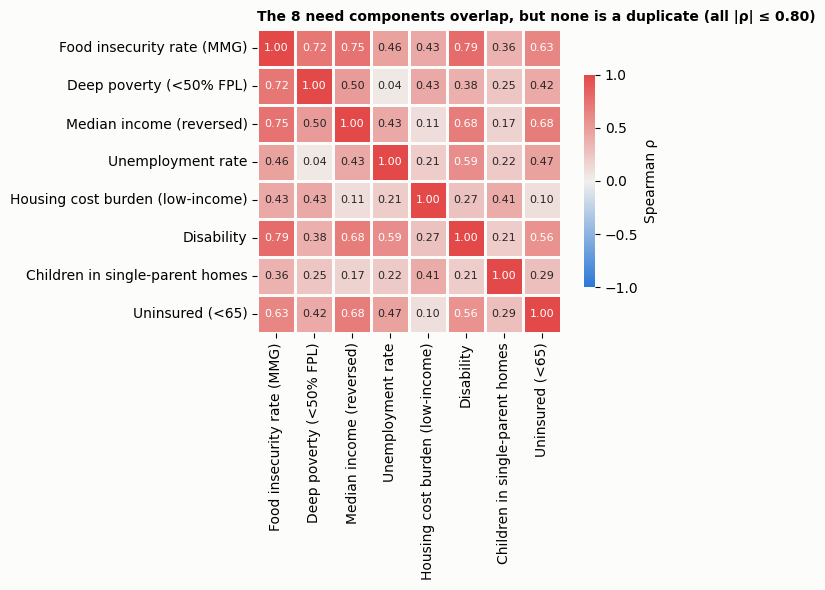

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 6))
sub = corr.loc[NEED_VARS, NEED_VARS].rename(index=LABEL, columns=LABEL)
sns.heatmap(sub, annot=True, fmt=".2f", cmap=DIV_CMAP, vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.7, "label": "Spearman ρ"},
            linewidths=1, linecolor="#fcfcfb", ax=ax, annot_kws={"fontsize": 8})
ax.set_title("The 8 need components overlap, but none is a duplicate (all |ρ| ≤ 0.80)", loc="left", fontsize=10)
ax.grid(False)
plt.tight_layout(); plt.show()

**Result:** 8 components, each a different side of hardship: food insecurity, deep poverty, low income, unemployment, housing cost burden, disability, single-parent families, no health insurance. The SAIPE poverty rate, child poverty and child FI were dropped because each correlates > 0.80 with the MMG food insecurity rate (MMG is itself modelled from poverty, unemployment, income, disability...). That overlap is expected and is checked in section 12 (leave-one-out, MMG-only baseline).

## 5. Three versions of the need index

All components are turned into **z-scores within each year** (0 = state county average, +1 = one standard deviation more need), so a 3-point unemployment rate and a $70,000 income are on the same scale.

1. **Equal-weight index**: the plain average of the 8 z-scores. Easy to explain: "every kind of hardship counts the same".
2. **PCA index**: Principal Component Analysis finds the single weighted mix of the 8 components that captures as much of their shared variation as possible (PC1). The weights (loadings) come from the data, not from us.
3. **MMG-only baseline**: just the food insecurity rate. Shows what we add beyond Map the Meal Gap.

The headline index is the 3-year average (2022-2024) of each county's yearly index. Yearly versions are kept for the stability check.

In [6]:
def zscore(s):
    return (s - s.mean()) / s.std(ddof=0)

for v in NEED_VARS:
    panel[f"z_{v}"] = panel.groupby("year")[v].transform(zscore)
ZV = [f"z_{v}" for v in NEED_VARS]
panel["need_ew"] = panel[ZV].mean(axis=1)
panel["need_mmg"] = panel["z_fi_rate"]

# PCA on the 3-year average of the standardized components (87 counties)
Zavg = panel.groupby("fips")[ZV].mean()
Zavg_std = (Zavg - Zavg.mean()) / Zavg.std(ddof=0)
pca = PCA().fit(Zavg_std)
load = pd.DataFrame(pca.components_.T, index=NEED_VARS, columns=[f"PC{i+1}" for i in range(len(NEED_VARS))])
sign = np.sign(load.loc["fi_rate", "PC1"])          # orient PC1 so that more food insecurity = more need
load["PC1"] *= sign
w_pc1 = load["PC1"]
# Apply the same PC1 weights to every year (comparable across years); centered/scaled like the fit data
panel["need_pca"] = ((panel[ZV] - Zavg.mean().values) / Zavg.std(ddof=0).values) @ w_pc1.values
expl = pd.Series(pca.explained_variance_ratio_, index=load.columns)
print("Explained variance:", (expl * 100).round(1).to_dict())
print("Eigenvalues:", pca.explained_variance_.round(2))
load[["PC1", "PC2"]].rename(index=LABEL).round(2)

Explained variance: {'PC1': 52.7, 'PC2': 14.8, 'PC3': 10.7, 'PC4': 10.0, 'PC5': 4.8, 'PC6': 4.0, 'PC7': 2.4, 'PC8': 0.6}
Eigenvalues: [4.26 1.2  0.87 0.81 0.39 0.33 0.19 0.05]


,PC1,PC2
Food insecurity rate (MMG),0.47,0.00
Deep poverty (<50% FPL),0.35,0.38
Median income (reversed),0.40,-0.24
Unemployment rate,0.30,-0.37
Housing cost burden (low-income),0.24,0.59
Disability,0.41,-0.27
Children in single-parent homes,0.26,0.44
Uninsured (<65),0.34,-0.22


**Reading the PCA.** PC1's loadings should all be positive if it is a general "hardship" factor. Any component with a small or negative PC1 loading is measuring something different from the rest (the PC2 column shows what). The scree plot shows how much variation each component captures; an eigenvalue above 1 means a component explains more than one original indicator would.

In [7]:
need = panel.groupby("fips")[list(dict.fromkeys(["need_ew", "need_pca", "need_mmg"] + NEED_VARS + ["pop_pep", "fi_rate"]))].mean()
need["county"] = need.index.map(COUNTY)
V3 = {"need_ew": "Equal weight", "need_pca": "PCA (PC1)", "need_mmg": "MMG only"}
agree = need[list(V3)].corr(method="spearman").rename(index=V3, columns=V3).round(3)
top10 = {k: set(need[k].nlargest(10).index) for k in V3}
overlap = pd.DataFrame([[len(top10[a] & top10[b]) for b in V3] for a in V3], index=V3.values(), columns=V3.values())
print("Spearman agreement between need versions:"); display(agree)
print("Top-10 overlap (out of 10):"); display(overlap)

rho_ew_pca = need["need_ew"].corr(need["need_pca"], method="spearman")
pc1_share = expl["PC1"]
if rho_ew_pca >= 0.95 and len(top10["need_ew"] & top10["need_pca"]) >= 8:
    HEADLINE, why = "need_ew", "equal-weight and PCA rank counties almost identically, so we use the easier-to-explain equal weights"
elif pc1_share >= 0.5:
    HEADLINE, why = "need_pca", "PC1 is one clearly dominant factor and the rankings differ, so we use the data-driven weights"
else:
    HEADLINE, why = "need_ew", "no single dominant factor, so we avoid letting PCA pick weights"
print(f"\nPC1 explains {pc1_share:.0%}; rho(EW, PCA) = {rho_ew_pca:.3f} -> headline = {V3[HEADLINE]}: {why}.")

Spearman agreement between need versions:


,Equal weight,PCA (PC1),MMG only
Equal weight,1.000,0.991,0.926
PCA (PC1),0.991,1.000,0.950
MMG only,0.926,0.950,1.000


Top-10 overlap (out of 10):


,Equal weight,PCA (PC1),MMG only
Equal weight,10,10,7
PCA (PC1),10,10,7
MMG only,7,7,10



PC1 explains 53%; rho(EW, PCA) = 0.991 -> headline = Equal weight: equal-weight and PCA rank counties almost identically, so we use the easier-to-explain equal weights.


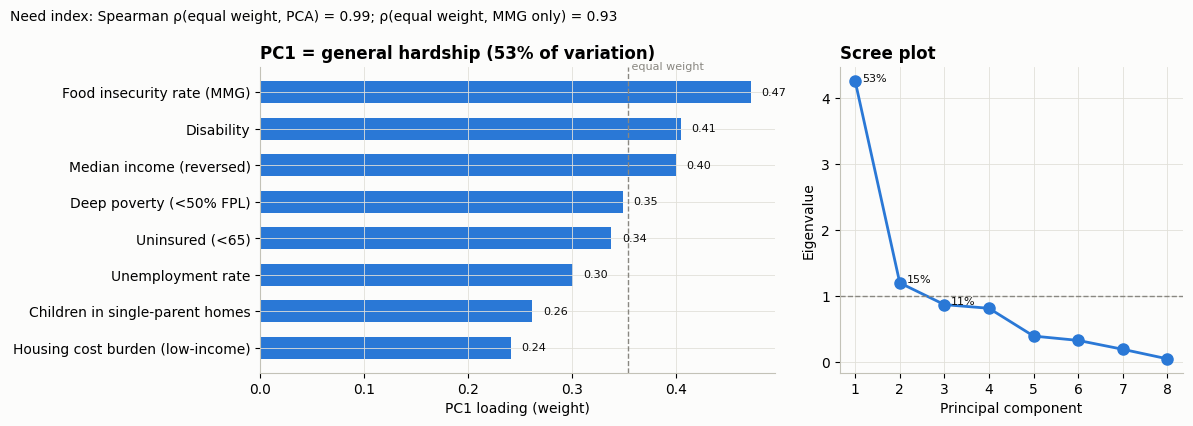

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
lp = w_pc1.rename(index=LABEL).sort_values()
ax.barh(lp.index, lp.values, color="#2a78d6", height=0.6)
ax.axvline(1 / np.sqrt(len(NEED_VARS)), color=MUTED, ls="--", lw=1)
ax.text(1 / np.sqrt(len(NEED_VARS)), len(NEED_VARS) - 0.45, " equal weight", color=MUTED, fontsize=8, va="bottom")
ax.set_xlabel("PC1 loading (weight)")
ax.set_title(f"PC1 = general hardship ({pc1_share:.0%} of variation)", loc="left")
for y, v in enumerate(lp.values):
    ax.text(v + 0.01, y, f"{v:.2f}", va="center", fontsize=8, color=INK)
ax = axes[1]
ax.plot(range(1, len(expl) + 1), pca.explained_variance_, marker="o", color="#2a78d6", lw=2, ms=8)
ax.axhline(1, color=MUTED, ls="--", lw=1)
ax.set_xticks(range(1, len(expl) + 1)); ax.set_xlabel("Principal component"); ax.set_ylabel("Eigenvalue")
ax.set_title("Scree plot", loc="left")
for i, e in enumerate(expl.values[:3]):
    ax.text(i + 1.15, pca.explained_variance_[i], f"{e:.0%}", fontsize=8, color=INK)
fig.suptitle(f"Need index: Spearman ρ(equal weight, PCA) = {rho_ew_pca:.2f}; ρ(equal weight, MMG only) = {agree.iloc[0, 2]:.2f}",
             x=0.01, ha="left", fontsize=10)
plt.tight_layout()
fig.savefig(OUT / "q6_need_index_pca.png", dpi=200, bbox_inches="tight"); plt.show()

## 6. Count version: how many people are in need?

An index tells *where need is relatively high*; for allocating food you also need *how many people*. We express the headline index on the food insecurity scale: regress the 3-year MMG `fi_rate` on the index and use the fitted value as a **need-adjusted rate** (it keeps MMG's level but lets the other 7 indicators move counties up or down). Persons in need = need-adjusted rate × population.

In [9]:
cal = smf.ols("fi_rate ~ idx", data=need.assign(idx=need[HEADLINE])).fit()
need["need_rate_adj"] = cal.fittedvalues.clip(lower=0.01)
need["need_persons"] = need["need_rate_adj"] * need["pop_pep"]
print(f"Calibration fi_rate = {cal.params['Intercept']:.3f} + {cal.params['idx']:.3f} x index (R² = {cal.rsquared:.2f})")
print(f"Statewide persons in need (sum): {need['need_persons'].sum():,.0f}  vs MMG fi_persons-equivalent {(need['fi_rate'] * need['pop_pep']).sum():,.0f}")
need.sort_values("need_persons", ascending=False)[["county", "pop_pep", "fi_rate", "need_rate_adj", "need_persons"]].head(8).round(3)

Calibration fi_rate = 0.110 + 0.023 x index (R² = 0.91)
Statewide persons in need (sum): 596,007  vs MMG fi_persons-equivalent 578,752


,county,pop_pep,fi_rate,need_rate_adj,need_persons
fips,,,,,
27053,Hennepin,1265175.000,0.101,0.105,132529.105
27123,Ramsey,539639.667,0.118,0.123,66531.256
27037,Dakota,448544.333,0.083,0.088,39630.535
27003,Anoka,373136.333,0.082,0.092,34247.716
27137,St. Louis,200336.667,0.126,0.127,25486.033
27163,Washington,279962.667,0.074,0.077,21607.887
27145,Stearns,162204.333,0.112,0.110,17843.500
27109,Olmsted,165231.333,0.091,0.091,15047.528


## 7. Demand: the three food shelf metrics, per resident

Annual totals per county from `foodshelf_county_month.csv` (meal programs excluded), divided by Census July population (`pop_pep`) → **per 1,000 residents**. Handling of missing reports follows Q1:
- a county-year with **no** reported month is missing, not zero (Wilkin: no food shelf at all);
- a county-year with < 12 reported months or > 10% of site-months unreported is flagged `incomplete` (its total is too low). For the 3-year average we use only complete years when a county has at least one.

Each metric is kept separately. Activity per resident is right-skewed (a few hub counties), so we take **logs**, then a **robust z** (median and MAD instead of mean and SD) so a single hub can't stretch the scale. **Combined demand** = average of the three robust z's.

In [10]:
fs = fs_month[fs_month["month"].dt.year.between(2022, 2024)].assign(year=lambda d: d["month"].dt.year)
fy = (fs.groupby(["fips", "year"])
        .agg(visits=("visits", "sum"), pounds=("pounds", "sum"), individuals=("individuals", "sum"),
             months_reported=("visits", lambda s: s.notna().sum()), site_months=("n_sites", "sum"),
             site_months_missing=("n_sites_missing", "sum"))
        .reset_index())
fy.loc[fy["months_reported"] == 0, METRICS] = np.nan
fy["incomplete"] = (fy["months_reported"] > 0) & ((fy["months_reported"] < 12) |
                                                   (fy["site_months_missing"] / fy["site_months"].replace(0, np.nan) > 0.10))
fy = fy.merge(fac_y[["fips", "year", "pop_pep"]], on=["fips", "year"], validate="one_to_one")
for m in METRICS:
    fy[f"{m}_per_1k"] = fy[m] / fy["pop_pep"] * 1000
print("Incomplete county-years:", fy.loc[fy["incomplete"], ["fips", "year"]].assign(county=lambda d: d["fips"].map(COUNTY)).values.tolist())

PER1K = [f"{m}_per_1k" for m in METRICS]
def avg_demand(g):
    ok = g[~g["incomplete"]] if (~g["incomplete"]).any() else g
    return pd.Series({**ok[PER1K].mean().to_dict(), "n_years_used": len(ok), "any_incomplete": g["incomplete"].any()})
dem = fy.groupby("fips").apply(avg_demand)

def robust_z(s):
    med = s.median(); mad = (s - med).abs().median() * 1.4826
    return (s - med) / mad

def demand_scores(d):
    out = pd.DataFrame(index=d.index)
    for m in METRICS:
        out[f"dz_{m}"] = robust_z(np.log(d[f"{m}_per_1k"]))
    out["dz_combined"] = out[[f"dz_{m}" for m in METRICS]].mean(axis=1)
    return out

dem = dem.join(demand_scores(dem.dropna(subset=PER1K)))
print("Counties with demand:", dem["dz_combined"].notna().sum(), "| no food shelf:", dem.index[dem["dz_combined"].isna()].map(COUNTY).tolist())
print("Spearman among the three demand metrics (per 1k):")
dem[PER1K].corr(method="spearman").round(2)

Incomplete county-years: [['27007', 2022, 'Beltrami'], ['27007', 2023, 'Beltrami'], ['27007', 2024, 'Beltrami'], ['27011', 2022, 'Big Stone'], ['27041', 2023, 'Douglas'], ['27051', 2022, 'Grant'], ['27149', 2024, 'Stevens']]
Counties with demand: 86 | no food shelf: ['Wilkin']
Spearman among the three demand metrics (per 1k):


,visits_per_1k,pounds_per_1k,individuals_per_1k
visits_per_1k,1.00,0.83,0.94
pounds_per_1k,0.83,1.00,0.87
individuals_per_1k,0.94,0.87,1.00


## 8. Need vs. demand: how much do they agree?

Same question as Q1, now with the broader need index. If need and demand rose together, divergence would be small and mostly noise.

In [11]:
cty = need.join(dem)
scored = cty[cty["dz_combined"].notna()].copy()     # 86 counties (Wilkin has no food shelf)
rows = []
for nv in V3:
    for m in METRICS + ["combined"]:
        col = f"dz_{m}"
        r, p = stats.spearmanr(scored[nv], scored[col])
        rows.append({"need version": V3[nv], "metric": NICE[m], "rho": round(r, 2), "p": round(p, 3)})
need_dem = pd.DataFrame(rows).pivot(index="need version", columns="metric", values="rho")[[NICE[m] for m in METRICS + ["combined"]]]
need_dem

metric,Visits,Pounds,Individuals,Combined
need version,,,,
Equal weight,0.11,0.10,0.09,0.11
MMG only,0.06,0.12,0.07,0.09
PCA (PC1),0.08,0.08,0.07,0.09


Per resident, need and demand barely move together, confirming Q1 with a broader need measure. This is why a divergence measure is informative: knowing a county's need tells you little about how much food shelf activity it records.

## 9. The divergence measure

**Main version, rank gap:** for each county,

> **divergence = need percentile − demand percentile** (both among the 86 counties with a food shelf, 0-100).

- **Positive** (e.g. +60): the county ranks much higher on need than on food shelf activity → **potentially underserved**: need likely larger than activity shows (latent demand, unmet demand, or need met elsewhere).
- **Negative**: activity above what need suggests → busy regional hubs, cross-county inflow, or users who are not food insecure (the Urban Institute finds over a third of charitable food users are food secure).

Ranks make it robust: one extreme county can't dominate. Computed for each metric and for combined demand.

**Check versions:**
- **Robust-z gap**: robust z of need − robust z of demand (keeps distances, not just order).
- **Regression residual**: regress log activity per resident on the need index; a county far *below* the line has less activity than its need predicts. Divergence = − standardized residual.

In [12]:
def pct(s):
    return s.rank(pct=True) * 100

def divergence(d, need_col, dz_prefix="dz_"):
    """Rank-gap divergence for each metric + combined. d: one row per county."""
    out = pd.DataFrame(index=d.index)
    out["need_pctile"] = pct(d[need_col])
    for m in METRICS + ["combined"]:
        out[f"dem_pctile_{m}"] = pct(d[f"{dz_prefix}{m}"])
        out[f"div_{m}"] = out["need_pctile"] - out[f"dem_pctile_{m}"]
    return out

div = divergence(scored, HEADLINE)
scored = scored.join(div)
need_rz = robust_z(scored[HEADLINE])
scored["div_z_combined"] = need_rz - scored["dz_combined"]
for m in METRICS + ["combined"]:
    y = np.log(scored[f"{m}_per_1k"]) if m != "combined" else scored["dz_combined"]
    fit = smf.ols("y ~ x", data=pd.DataFrame({"y": y, "x": scored[HEADLINE]})).fit()
    scored[f"div_resid_{m}"] = -(fit.resid / fit.resid.std())
    if m == "combined":
        resid_slope, resid_r2 = fit.params["x"], fit.rsquared

check = pd.DataFrame({
    "rank gap vs robust-z gap": [scored["div_combined"].corr(scored["div_z_combined"], method="spearman")],
    "rank gap vs regression residual": [scored["div_combined"].corr(scored["div_resid_combined"], method="spearman")],
    "top-15 overlap (rank gap, robust z)": [len(set(scored["div_combined"].nlargest(TOP_N).index) & set(scored["div_z_combined"].nlargest(TOP_N).index))],
    "top-15 overlap (rank gap, residual)": [len(set(scored["div_combined"].nlargest(TOP_N).index) & set(scored["div_resid_combined"].nlargest(TOP_N).index))],
}).T.rename(columns={0: "value"}).round(3)
print(f"Regression of combined demand on need: slope = {resid_slope:.2f}, R² = {resid_r2:.3f}")
check

Regression of combined demand on need: slope = 0.21, R² = 0.016


,value
rank gap vs robust-z gap,0.964
rank gap vs regression residual,0.742
"top-15 overlap (rank gap, robust z)",9.000
"top-15 overlap (rank gap, residual)",8.000


The rank gap and the robust-z gap agree almost perfectly, so using ranks doesn't distort anything. The regression-residual version agrees less (it shares about half to two-thirds of the top 15): because need explains almost none of the variation in demand (R² near 0), the fitted line is nearly flat and the residual becomes close to "low activity, whatever the need". The rank gap gives need an explicit, equal say, which is what the question asks for, so it is the headline; the residual version is kept in the output file.

**What drives divergence?** Divergence has two parts, need and (minus) demand. Because the two are nearly uncorrelated, each contributes about equally (ρ ≈ +0.65 with need, −0.65 with activity). So a high score needs **both** high need **and** low activity; low activity alone is not enough.

In [13]:
decomp = pd.DataFrame({m: {"rho with need percentile": scored[f"div_{m}"].corr(scored["need_pctile"], method="spearman"),
                           "rho with demand percentile": scored[f"div_{m}"].corr(scored[f"dem_pctile_{m}"], method="spearman")}
                       for m in METRICS + ["combined"]}).rename(columns=NICE).round(2)
per_metric_agree = scored[[f"div_{m}" for m in METRICS]].corr(method="spearman").round(2)
display(decomp)
print("Agreement of divergence across the three metrics (Spearman):"); per_metric_agree

,Visits,Pounds,Individuals,Combined
rho with need percentile,0.65,0.65,0.65,0.65
rho with demand percentile,-0.65,-0.67,-0.67,-0.65


Agreement of divergence across the three metrics (Spearman):


,div_visits,div_pounds,div_individuals
div_visits,1.00,0.85,0.94
div_pounds,0.85,1.00,0.90
div_individuals,0.94,0.90,1.00


## 10. Which counties diverge?

In [14]:
show = ["county", "pop_pep", "need_pctile", "dem_pctile_combined", "div_visits", "div_pounds", "div_individuals", "div_combined"]
print("Need above activity (potentially underserved), top 15:")
display(scored.sort_values("div_combined", ascending=False)[show].head(TOP_N).round(0))
print("Activity above need, top 15:")
display(scored.sort_values("div_combined")[show].head(TOP_N).round(0))

Need above activity (potentially underserved), top 15:


,county,pop_pep,need_pctile,dem_pctile_combined,div_visits,div_pounds,div_individuals,div_combined
fips,,,,,,,,
27151,Swift,9709.0,94.0,12.0,77.0,86.0,77.0,83.0
27105,Nobles,21973.0,92.0,16.0,79.0,80.0,53.0,76.0
27159,Wadena,14338.0,90.0,27.0,63.0,67.0,58.0,63.0
27023,Chippewa,12300.0,85.0,22.0,55.0,71.0,52.0,63.0
27107,Norman,6319.0,66.0,5.0,63.0,65.0,62.0,62.0
27153,Todd,25765.0,73.0,14.0,62.0,52.0,58.0,59.0
27001,Aitkin,16205.0,98.0,42.0,48.0,69.0,58.0,56.0
27029,Clearwater,8649.0,99.0,47.0,47.0,45.0,52.0,52.0
27051,Grant,6133.0,71.0,20.0,51.0,36.0,57.0,51.0


Activity above need, top 15:


,county,pop_pep,need_pctile,dem_pctile_combined,div_visits,div_pounds,div_individuals,div_combined
fips,,,,,,,,
27163,Washington,279963.0,3.0,98.0,-94.0,-87.0,-95.0,-94.0
27109,Olmsted,165231.0,10.0,92.0,-81.0,-83.0,-80.0,-81.0
27003,Anoka,373136.0,12.0,90.0,-78.0,-65.0,-84.0,-78.0
27147,Steele,37460.0,31.0,100.0,-69.0,-67.0,-69.0,-69.0
27039,Dodge,21127.0,6.0,74.0,-73.0,-52.0,-71.0,-69.0
27131,Rice,68380.0,30.0,99.0,-69.0,-67.0,-67.0,-69.0
27069,Kittson,4023.0,14.0,78.0,-64.0,-70.0,-56.0,-64.0
27141,Sherburne,101996.0,7.0,71.0,-63.0,-56.0,-69.0,-64.0
27157,Wabasha,21638.0,17.0,80.0,-63.0,-64.0,-63.0,-63.0


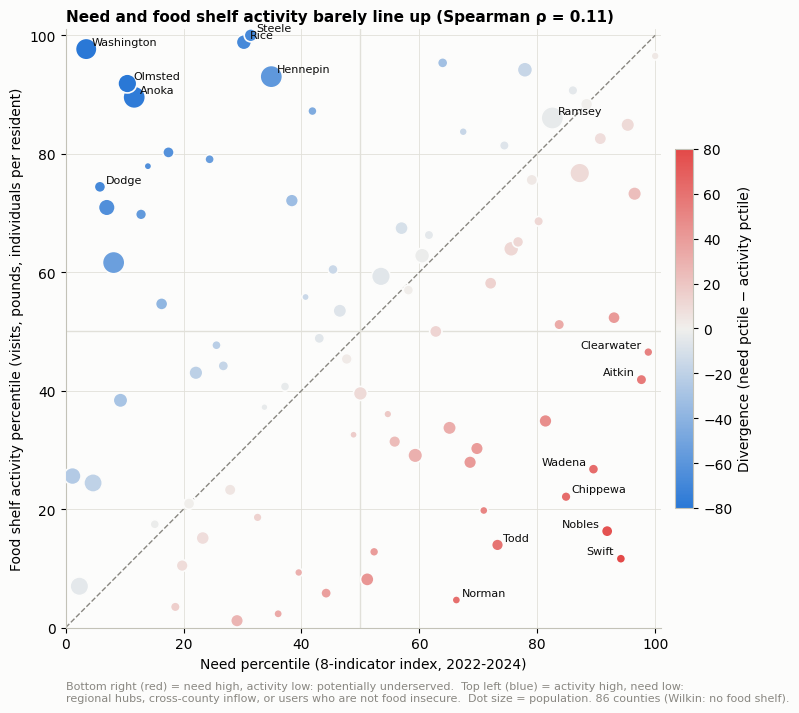

In [15]:
fig, ax = plt.subplots(figsize=(8.6, 7.2))
x, y = scored["need_pctile"], scored["dem_pctile_combined"]
c = scored["div_combined"]
ax.plot([0, 100], [0, 100], color=MUTED, lw=1, ls="--")
ax.axhline(50, color=GRID, lw=1); ax.axvline(50, color=GRID, lw=1)
sc = ax.scatter(x, y, c=c, cmap=DIV_CMAP, vmin=-80, vmax=80, s=np.clip(np.sqrt(scored["pop_pep"]) / 2.2, 14, 260),
                edgecolor="#fcfcfb", linewidth=1.2, zorder=3)
lab = list(scored["div_combined"].nlargest(8).index) + list(scored["div_combined"].nsmallest(6).index) + \
      [f for f in scored.index if COUNTY[f] in ("Hennepin", "Ramsey")]
for f in dict.fromkeys(lab):
    right = x[f] > 88
    ax.annotate(COUNTY[f], (x[f], y[f]), xytext=(-5 if right else 4, 3), textcoords="offset points", fontsize=8, color=INK,
                ha="right" if right else "left")
ax.set_xlim(0, 101); ax.set_ylim(0, 101)
ax.set_xlabel("Need percentile (8-indicator index, 2022-2024)")
ax.set_ylabel("Food shelf activity percentile (visits, pounds, individuals per resident)")
ax.set_title(f"Need and food shelf activity barely line up (Spearman ρ = {scored[HEADLINE].corr(scored['dz_combined'], method='spearman'):.2f})",
             loc="left", fontsize=11)
cb = plt.colorbar(sc, ax=ax, shrink=0.6, pad=0.02); cb.set_label("Divergence (need pctile − activity pctile)")
ax.text(0, -0.09, "Bottom right (red) = need high, activity low: potentially underserved.  Top left (blue) = activity high, need low:\n"
        "regional hubs, cross-county inflow, or users who are not food insecure.  Dot size = population. 86 counties (Wilkin: no food shelf).",
        transform=ax.transAxes, fontsize=8, color=MUTED, va="top")
plt.tight_layout()
fig.savefig(OUT / "q6_need_vs_activity_quadrant.png", dpi=200, bbox_inches="tight"); plt.show()

## 10b. A companion in plain numbers: how much of the meal gap do food shelves cover?

The divergence score is a **rank** (good for comparing counties, hard to say out loud). This companion turns it into a sentence: *"food shelves in county X give out about N% of the meals its food-insecure residents are short."*

- **Meal gap** (Feeding America, Map the Meal Gap): `annual_food_budget_shortfall ÷ cost_per_meal` = the number of meals food-insecure residents are short in a year. MMG already assumes people are food insecure for only part of the year (the shortfall equals about 7 of 12 months of the weekly shortfall), and the weekly shortfall is about 6 meals per food-insecure person.
- **Food shelf meals** = pounds distributed ÷ **1.2** (Feeding America's standard conversion: **1.2 pounds of food ≈ 1 meal**, used in its annual reports and by member food banks).
- **Coverage** = food shelf meals ÷ meal gap. 1.0 = enough pounds to fill the whole gap; 0.25 = a quarter of it.

**Years.** Headline **2024**, with **2023 as a check**. MMG changed its cost-per-meal method in 2023, so 2022 costs are not comparable with 2023/2024. We only compare counties **within the same year**, never 2022 with 2024.

**Caveats (say them on the slide):**
1. 1.2 lb/meal is an approximation (fresh produce is heavy, dry goods light).
2. Food shelves also serve people who are **not** food insecure (Urban Institute: over a third of charitable food users are food secure), so coverage is an **upper bound** on how much of the *food-insecure* gap is filled.
3. Pounds are counted where the **food shelf** is, not where clients live (section 11): hub counties look over-covered, their neighbours under-covered.
4. **Wilkin** has no food shelf in the data, so it has no coverage value (its residents use shelves in neighbouring counties).
5. A county-year with incomplete reporting has its pounds (and coverage) understated; flagged.

In [16]:
FI_LB_PER_MEAL = 1.2
cov_y = (mmg[["fips", "year", "fi_persons", "annual_food_budget_shortfall", "cost_per_meal", "weekly_dollars_needed_per_fi"]]
         .merge(fy[["fips", "year", "pounds", "individuals", "visits", "incomplete"]], on=["fips", "year"], how="left"))
cov_y = cov_y[cov_y["year"].isin([2023, 2024])].copy()
cov_y["meal_gap_meals"] = cov_y["annual_food_budget_shortfall"] / cov_y["cost_per_meal"]
cov_y["foodshelf_meals"] = cov_y["pounds"] / FI_LB_PER_MEAL
cov_y["coverage"] = cov_y["foodshelf_meals"] / cov_y["meal_gap_meals"]
cov_y["indiv_per_fi"] = cov_y["individuals"] / cov_y["fi_persons"]      # person-visits per food-insecure resident per year
cov_y["visits_per_fi"] = cov_y["visits"] / cov_y["fi_persons"]
print("Weekly meals short per food-insecure person (median):",
      round((cov_y["weekly_dollars_needed_per_fi"] / cov_y["cost_per_meal"]).median(), 1),
      "| share of the year MMG counts as food insecure:",
      round((cov_y["annual_food_budget_shortfall"] / (cov_y["weekly_dollars_needed_per_fi"] * 52 * cov_y["fi_persons"])).median(), 3))
for yr in [2023, 2024]:
    c = cov_y[cov_y["year"] == yr]
    print(f"{yr}: statewide coverage (sum of counties) = {c['foodshelf_meals'].sum() / c['meal_gap_meals'].sum():.2f} | "
          f"county median = {c['coverage'].median():.2f} | counties < 0.5: {(c['coverage'] < 0.5).sum()} | > 1: {(c['coverage'] > 1).sum()} | "
          f"incomplete county-years: {int(c['incomplete'].fillna(False).sum())}")
cov = cov_y.pivot(index="fips", columns="year", values=["meal_gap_meals", "foodshelf_meals", "coverage", "indiv_per_fi", "visits_per_fi"]).astype(float)
cov.columns = [f"{a}_{b}" for a, b in cov.columns]
for yr in [2023, 2024]:
    cov[f"incomplete_{yr}"] = cov_y[cov_y["year"] == yr].set_index("fips")["incomplete"].fillna(False).astype(bool)
cov["county"] = cov.index.map(COUNTY)
print("Spearman coverage 2023 vs 2024:", round(cov["coverage_2023"].corr(cov["coverage_2024"], method="spearman"), 3))
show_c = ["county", "meal_gap_meals_2024", "foodshelf_meals_2024", "coverage_2024", "coverage_2023", "indiv_per_fi_2024", "incomplete_2024"]
print("Lowest coverage 2024:"); display(cov.sort_values("coverage_2024")[show_c].head(10).round(2))
print("Highest coverage 2024:"); display(cov.sort_values("coverage_2024", ascending=False)[show_c].head(6).round(2))

Weekly meals short per food-insecure person (median): 6.3 | share of the year MMG counts as food insecure: 0.583
2023: statewide coverage (sum of counties) = 1.06 | county median = 0.67 | counties < 0.5: 25 | > 1: 17 | incomplete county-years: 2
2024: statewide coverage (sum of counties) = 1.07 | county median = 0.63 | counties < 0.5: 24 | > 1: 16 | incomplete county-years: 2
Spearman coverage 2023 vs 2024: 0.89
Lowest coverage 2024:


,county,meal_gap_meals_2024,foodshelf_meals_2024,coverage_2024,coverage_2023,indiv_per_fi_2024,incomplete_2024
fips,,,,,,,
27107,Norman,146214.10,28214.00,0.19,0.20,2.33,False
27149,Stevens,241298.70,49943.33,0.21,0.61,3.13,True
27139,Scott,2095476.19,445999.17,0.21,0.98,2.32,False
27151,Swift,290322.58,63318.33,0.22,0.30,3.35,False
27103,Nicollet,729439.25,170383.33,0.23,0.23,2.47,False
27081,Lincoln,128961.75,31523.33,0.24,0.25,2.86,False
27073,Lac qui Parle,142349.73,38981.67,0.27,0.24,1.61,False
27023,Chippewa,343548.39,100280.83,0.29,0.27,4.57,False
27135,Roseau,341388.89,102866.67,0.30,0.24,3.78,False


Highest coverage 2024:


,county,meal_gap_meals_2024,foodshelf_meals_2024,coverage_2024,coverage_2023,indiv_per_fi_2024,incomplete_2024
fips,,,,,,,
27147,Steele,779187.82,2073742.83,2.66,2.24,44.19,False
27131,Rice,1422141.12,3642482.50,2.56,2.13,36.34,False
27163,Washington,4270263.79,8637615.00,2.02,2.03,49.66,False
27109,Olmsted,3132315.52,6239883.98,1.99,1.50,22.03,False
27013,Blue Earth,1745316.46,3043620.83,1.74,1.47,16.55,False
27117,Pipestone,218206.52,358785.00,1.64,1.53,13.72,False


In [17]:
# Agreement with the divergence score (86 counties)
J = scored.join(cov[["coverage_2024", "coverage_2023", "indiv_per_fi_2024"]])
agree_cov = pd.DataFrame({k: {"Spearman with coverage 2024": J[k].corr(J["coverage_2024"], method="spearman"),
                              "Spearman with coverage 2023": J[k].corr(J["coverage_2023"], method="spearman")}
                          for k in ["div_pounds", "div_combined", "div_individuals", "need_pctile", "dem_pctile_pounds"]}).T.round(2)
display(agree_cov)
low15 = set(J["coverage_2024"].nsmallest(TOP_N).index); top15 = set(J["div_combined"].nlargest(TOP_N).index)
print(f"Overlap: {len(low15 & top15)} of the 15 lowest-coverage counties are in the headline top-15 'need above activity'.")
print("In the top 15 by divergence but NOT lowest-15 coverage:", sorted(J.loc[list(top15 - low15), "county"]))
print("Lowest-15 coverage but NOT top-15 divergence:", sorted(J.loc[list(low15 - top15), "county"]))
print("Individuals (person-visits) per food-insecure resident 2024 vs coverage 2024, Spearman:",
      round(J["indiv_per_fi_2024"].corr(J["coverage_2024"], method="spearman"), 2),
      "| vs div_individuals:", round(J["indiv_per_fi_2024"].corr(J["div_individuals"], method="spearman"), 2))

,Spearman with coverage 2024,Spearman with coverage 2023
div_pounds,-0.80,-0.81
div_combined,-0.77,-0.78
div_individuals,-0.73,-0.72
need_pctile,-0.23,-0.19
dem_pctile_pounds,0.86,0.89


Overlap: 8 of the 15 lowest-coverage counties are in the headline top-15 'need above activity'.
In the top 15 by divergence but NOT lowest-15 coverage: ['Becker', 'Carlton', 'Clearwater', 'Grant', 'Morrison', 'Pine', 'Todd']
Lowest-15 coverage but NOT top-15 divergence: ['Lac qui Parle', 'Lincoln', 'Nicollet', 'Pope', 'Roseau', 'Scott', 'Stevens']
Individuals (person-visits) per food-insecure resident 2024 vs coverage 2024, Spearman: 0.87 | vs div_individuals: -0.8


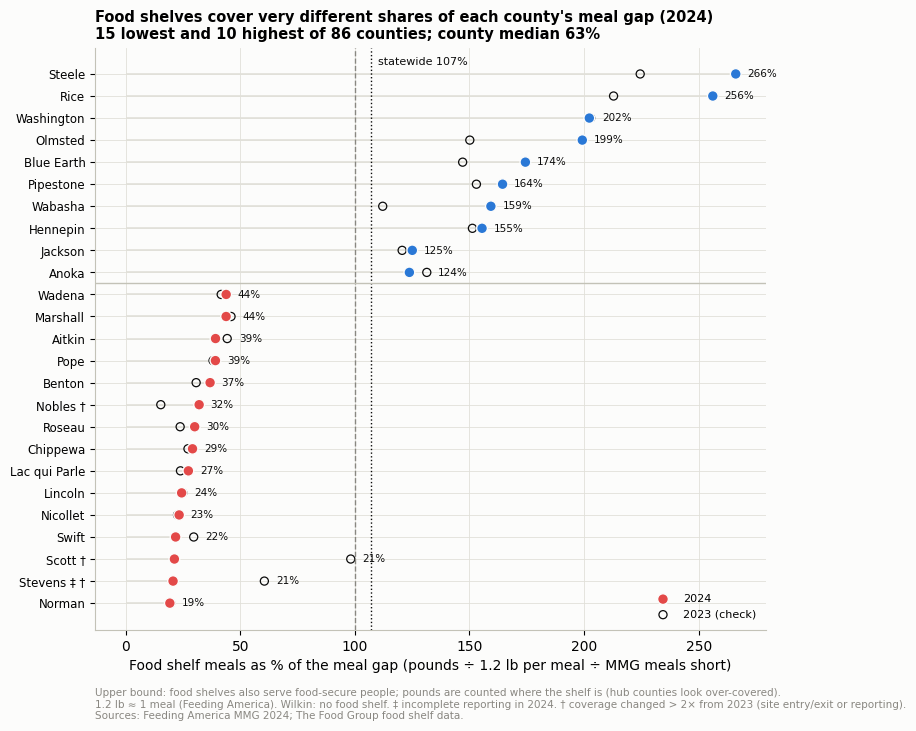

In [18]:
c24 = cov.dropna(subset=["coverage_2024"]).sort_values("coverage_2024")
state24 = cov_y.loc[cov_y.year == 2024, "foodshelf_meals"].sum() / cov_y.loc[cov_y.year == 2024, "meal_gap_meals"].sum()
pick = pd.concat([c24.head(15), c24.tail(10)])
fig, ax = plt.subplots(figsize=(9, 7.4))
yy = np.arange(len(pick))
cols = [UNDER if v < 0.5 else (OVER if v > 1 else "#898781") for v in pick["coverage_2024"]]
ax.hlines(yy, 0, pick["coverage_2024"] * 100, color=GRID, lw=1.2, zorder=1)
ax.scatter(pick["coverage_2024"] * 100, yy, color=cols, s=60, zorder=3, edgecolor="#fcfcfb", linewidth=1, label="2024")
ax.scatter(pick["coverage_2023"] * 100, yy, facecolor="none", edgecolor=INK, s=34, zorder=2, linewidth=0.9, label="2023 (check)")
ax.axvline(100, color=MUTED, ls="--", lw=1); ax.axvline(state24 * 100, color=INK, ls=":", lw=1)
ax.text(state24 * 100 + 3, len(pick) - 0.6, f"statewide {state24:.0%}", fontsize=8, color=INK)
ax.axhline(14.5, color="#c3c2b7", lw=1)
ax.set_yticks(yy)
jump = lambda r: max(r.coverage_2024, r.coverage_2023) / min(r.coverage_2024, r.coverage_2023) > 2
ax.set_yticklabels([f"{r.county}{' ‡' if bool(r.incomplete_2024) else ''}{' †' if jump(r) else ''}" for r in pick.itertuples()], fontsize=8.5)
for y_, v, v23 in zip(yy, pick["coverage_2024"], pick["coverage_2023"]):
    ax.text(max(v, v23) * 100 + 5, y_, f"{v:.0%}", va="center", fontsize=7.5, color=INK)
ax.set_xlabel("Food shelf meals as % of the meal gap (pounds ÷ 1.2 lb per meal ÷ MMG meals short)")
ax.set_title(f"Food shelves cover very different shares of each county's meal gap (2024)\n15 lowest and 10 highest of 86 counties; county median {c24['coverage_2024'].median():.0%}",
             loc="left", fontsize=10.5)
ax.legend(frameon=False, loc="lower right", fontsize=8)
ax.text(0, -0.1, "Upper bound: food shelves also serve food-secure people; pounds are counted where the shelf is (hub counties look over-covered).\n"
        "1.2 lb ≈ 1 meal (Feeding America). Wilkin: no food shelf. ‡ incomplete reporting in 2024. † coverage changed > 2× from 2023 (site entry/exit or reporting).\n"
        "Sources: Feeding America MMG 2024; The Food Group food shelf data.",
        transform=ax.transAxes, fontsize=7.5, color=MUTED, va="top")
plt.tight_layout()
fig.savefig(OUT / "q6_meal_gap_coverage.png", dpi=200, bbox_inches="tight"); plt.show()

**Result.**
- **Statewide, food shelves give out about as many meals as the meal gap** (2024: **107%**; 2023: 106%). That does **not** mean the gap is closed: some of the food goes to people who are not food insecure, and it is spread very unevenly.
- **The typical county covers well under its gap:** county median **63%** (2023: 67%). 24 of 86 counties are below 50%; 16 are above 100%.
- **Lowest (2024): Norman 19%, Stevens 21%‡, Scott 21%†, Swift 22%, Nicollet 23%, Lincoln 24%, Lac qui Parle 27%, Chippewa 29%.** Highest: **Steele 266%, Rice 256%, Washington 202%, Olmsted 199%, Blue Earth 174%**: regional hubs that also serve neighbours (Nicollet's nearest shelf is often in Blue Earth).
- **Two lows are partly artefacts.** Scott's largest site (≈1.9 million lb in 2023) has no rows in 2024, so Scott drops from 98% to 21%; Stevens has 3 unreported months in 2024 (‡). Use the 2023 value as a check for counties marked †.
- **Stable:** Spearman 0.89 between 2023 and 2024 coverage.
- **It tells the same story as the divergence score:** Spearman with divergence = **−0.80 (pounds)**, −0.77 (combined), −0.73 (individuals). 8 of the 15 lowest-coverage counties are in the headline top-15 "need above activity". The difference: coverage is driven by activity (ρ = +0.86 with the pounds percentile) and barely by need (ρ = −0.23), because the meal gap already scales with the number of food-insecure people. So coverage flags small-activity counties with *average* need (Scott, Nicollet, Lincoln, Lac qui Parle, Roseau, Pope, Stevens), while divergence adds counties whose need is high (Becker, Carlton, Clearwater, Morrison, Pine, Todd, Grant).
- **Visits/individuals analogue:** individuals served (person-visits; someone who comes every month counts 12 times) per food-insecure resident range from about 2 (Norman, Scott, Lac qui Parle) to 44–50 (Steele, Washington). It agrees with meal coverage (ρ = 0.87).

**Sentence for the slide:** *"In 2024, food shelves in Norman County gave out enough food for about 1 in 5 of the meals its food-insecure residents are short; in Steele County, more than 2½ times the gap, because Steele's shelves also serve neighbouring counties."*

## 11. Cross-county use: activity is counted where the food shelf is, not where clients live

Q1 found that for some counties most residents' **nearest** food shelf is across the county line (Nicollet → Mankato in Blue Earth). Then the shelf county looks busy and the home county looks "underserved" even if residents are served.

**Sensitivity: reallocate activity to where people live.** We rebuild Q1's distance inputs (section 28a there) and assume each fixed food shelf serves the residents for whom it is the **nearest** food shelf:
1. Census 2020 population-weighted centers of Minnesota's block groups;
2. each fixed food shelf's Census block (from `Organization.xlsx`), located with the Census TIGERweb service; sites whose block falls in a different county than they report are left in their reported county (as in Q1);
3. each site's 2022-2024 activity is split across the block groups that have it as their nearest site, in proportion to population, then summed by the block group's county. Sites that are nobody's nearest, outreach/mobile sites and unlocated sites stay in their reported county.

This is a crude model (people don't always use the nearest site; big sites attract from further away), so it is a **sensitivity**, not the headline. Downloads are cached in `Data/local/`.

In [19]:
import requests

realloc_ok = False
try:
    cenpop_file = LOCAL / "CenPop2020_Mean_BG27.txt"
    if not cenpop_file.exists():
        cenpop_file.write_bytes(requests.get("https://www2.census.gov/geo/docs/reference/cenpop2020/blkgrp/CenPop2020_Mean_BG27.txt", timeout=60).content)
    bgpop = pd.read_csv(cenpop_file, encoding="utf-8-sig", dtype=str)
    bgpop = bgpop.assign(fips=bgpop["STATEFP"] + bgpop["COUNTYFP"], population=bgpop["POPULATION"].astype(int),
                         lat=bgpop["LATITUDE"].astype(float), lon=bgpop["LONGITUDE"].astype(float))

    org = pd.read_excel(ROOT / "Data" / "Organization.xlsx", usecols=["__ID", "block_geoid"])
    site_m = pd.read_csv(PROCESSED / "foodshelf_site_month.csv", dtype={"fips": str})
    site_m = site_m[(site_m["site_group"] != "meal") & site_m["year"].between(2022, 2024)]
    sites = (site_m.groupby(["site_id", "year"])
             .agg(fips=("fips", lambda x: x.mode().iat[0]), agency_type=("agency_type", lambda x: x.mode().iat[0] if x.notna().any() else None),
                  visits=("visits", "sum"), pounds=("pounds", "sum"), individuals=("individuals", "sum")).reset_index()
             .merge(org, left_on="site_id", right_on="__ID", how="left"))
    sites["block"] = sites["block_geoid"].map(lambda v: f"{int(v):015d}" if pd.notna(v) else None)
    coords_file = LOCAL / "foodshelf_block_coords.csv"
    cached = pd.read_csv(coords_file, dtype={"GEOID": str}) if coords_file.exists() else pd.DataFrame(columns=["GEOID", "lat", "lon"])
    todo = sorted(set(sites["block"].dropna()) - set(cached["GEOID"]))
    URL = "https://tigerweb.geo.census.gov/arcgis/rest/services/TIGERweb/tigerWMS_Census2020/MapServer/10/query"
    got = []
    for i in range(0, len(todo), 50):
        q = "GEOID IN (%s)" % ",".join(f"'{b}'" for b in todo[i:i + 50])
        rep = requests.get(URL, params={"where": q, "outFields": "GEOID,INTPTLAT,INTPTLON", "returnGeometry": "false", "f": "json"}, timeout=60).json()
        got += [{"GEOID": f["attributes"]["GEOID"], "lat": float(f["attributes"]["INTPTLAT"]), "lon": float(f["attributes"]["INTPTLON"])} for f in rep["features"]]
    block_xy = pd.concat([d for d in (cached, pd.DataFrame(got, columns=["GEOID", "lat", "lon"])) if len(d)]).drop_duplicates("GEOID")
    block_xy.to_csv(coords_file, index=False)
    sites = sites.merge(block_xy, left_on="block", right_on="GEOID", how="left")
    FIXED = ["Food Shelf", "Brick and Mortar Site", "Brick and Mortar Sites", "Tribal Program", "College Campus Program"]
    sites["movable"] = sites["agency_type"].isin(FIXED) & sites["lat"].notna() & (sites["block"].str[:5] == sites["fips"])
    realloc_ok = True
except Exception as e:
    print("Reallocation inputs unavailable, falling back to the Q1 cross-county flag:", repr(e))

def miles(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 3958.8 * 2 * np.arcsin(np.sqrt(a))

if realloc_ok:
    res_rows = []
    for yr, s in sites.groupby("year"):
        mv = s[s["movable"] & (s["visits"].fillna(0) > 0)].reset_index(drop=True)
        d = miles(bgpop["lat"].values[:, None], bgpop["lon"].values[:, None], mv["lat"].values[None, :], mv["lon"].values[None, :])
        bg = bgpop.assign(site_idx=d.argmin(axis=1))
        bg["w"] = bg["population"] / bg.groupby("site_idx")["population"].transform("sum")
        alloc = bg.merge(mv[METRICS].reset_index().rename(columns={"index": "site_idx"}), on="site_idx")
        for m in METRICS:
            alloc[m] = alloc[m] * alloc["w"]
        moved = alloc.groupby("fips")[METRICS].sum()
        orphan = mv[~mv.index.isin(bg["site_idx"])].groupby("fips")[METRICS].sum()        # nobody's nearest: stays home
        stay = s[~s.index.isin(s[s["movable"] & (s["visits"].fillna(0) > 0)].index)].groupby("fips")[METRICS].sum(min_count=1)
        tot = moved.add(orphan, fill_value=0).add(stay, fill_value=0).assign(year=yr)
        res_rows.append(tot.reset_index())
    res = pd.concat(res_rows)
    print("Totals preserved:", {m: round(res[m].sum() / fy[m].sum(), 4) for m in METRICS})
    res = res.merge(fac_y[["fips", "year", "pop_pep"]], on=["fips", "year"]).merge(fy[["fips", "year", "incomplete"]], on=["fips", "year"], how="left")
    res["incomplete"] = res["incomplete"].fillna(False).astype(bool)
    for m in METRICS:
        res[f"{m}_per_1k"] = res[m] / res["pop_pep"] * 1000
    dem_res = res.groupby("fips").apply(avg_demand)
    dem_res = dem_res.join(demand_scores(dem_res[dem_res[PER1K].gt(0).all(axis=1)]))
    rs = need.join(dem_res[["dz_combined"] + [f"dz_{m}" for m in METRICS]], how="inner").dropna(subset=["dz_combined"])
    rs = rs.join(divergence(rs, HEADLINE))
    scored["div_combined_resident"] = rs["div_combined"]
    print(f"Counties scored after reallocation: {len(rs)} (Wilkin now receives activity from neighbours' food shelves)")
    print("Spearman(shelf-county divergence, resident-county divergence):",
          round(scored["div_combined"].corr(scored["div_combined_resident"], method="spearman"), 3))
    moved_cmp = scored[["county", "div_combined", "div_combined_resident"]].assign(change=lambda d: d["div_combined_resident"] - d["div_combined"])
    display(moved_cmp.reindex(moved_cmp["change"].abs().sort_values(ascending=False).index).head(10).round(0))
    if q1["fips"].isin(rs.index).any():
        wil = rs.loc[rs["county"] == "Wilkin"]
        if len(wil):
            print("Wilkin, using reallocated activity: divergence =", round(float(wil["div_combined"].iloc[0])))

Totals preserved: {'visits': 1.0, 'pounds': 1.0, 'individuals': 1.0}
Counties scored after reallocation: 87 (Wilkin now receives activity from neighbours' food shelves)
Spearman(shelf-county divergence, resident-county divergence): 0.905


,county,div_combined,div_combined_resident,change
fips,,,,
27103,Nicollet,28.0,-64.0,-92.0
27125,Red Lake,-15.0,36.0,51.0
27039,Dodge,-69.0,-29.0,40.0
27171,Wright,-20.0,-59.0,-39.0
27173,Yellow Medicine,-3.0,25.0,29.0
27143,Sibley,-17.0,-46.0,-29.0
27127,Redwood,-6.0,-32.0,-26.0
27005,Becker,41.0,16.0,-25.0
27029,Clearwater,52.0,29.0,-24.0


Wilkin, using reallocated activity: divergence = 40


## 12. Stability: does the top-15 list survive other reasonable choices?

We recompute the combined divergence under 15 alternative choices and count how often each county stays in the **top 15 potentially underserved** (and the top 15 activity-above-need):
- each **single year** 2022, 2023, 2024 (yearly need and demand);
- **PCA** weights and **MMG-only** need;
- **leave one component out** (8 versions);
- **drop the data-quality counties** (Douglas, Grant, Stevens: Q1 category B);
- **resident-county reallocation** (section 11).

A county in the top 15 in ≥ 75% of the versions it appears in is called **robust**.

In [20]:
DQ = q1.loc[q1["data_category"].fillna("").str.startswith("B"), "fips"].tolist()
variants = {"headline": scored["div_combined"]}
for yr in YEARS:
    py = panel[panel["year"] == yr].set_index("fips")
    fyy = fy[fy["year"] == yr].set_index("fips")
    d = py[[HEADLINE]].join(demand_scores(fyy.dropna(subset=PER1K)), how="inner")
    variants[f"year {yr}"] = divergence(d, HEADLINE)["div_combined"]
for alt in ["need_pca", "need_mmg"]:
    variants[V3[alt]] = divergence(scored, alt)["div_combined"]
for v in NEED_VARS:
    tmp = panel.assign(_n=panel[[z for z in ZV if z != f"z_{v}"]].mean(axis=1)).groupby("fips")["_n"].mean()
    variants[f"without {LABEL[v]}"] = divergence(scored.assign(_n=tmp), "_n")["div_combined"]
sub_ndq = scored.drop(index=[f for f in DQ if f in scored.index])
variants["drop data-quality counties"] = divergence(sub_ndq, HEADLINE)["div_combined"]
if realloc_ok:
    variants["resident-county reallocation"] = rs["div_combined"]
V = pd.DataFrame(variants)

def persistence(V, top=True):
    inn = pd.DataFrame({k: pd.Series(V.index.isin(V[k].nlargest(TOP_N).index if top else V[k].nsmallest(TOP_N).index), index=V.index)
                        for k in V})
    inn = inn.astype(float).where(V.notna())
    return (inn.sum(axis=1) / inn.notna().sum(axis=1)).astype(float)

stab = pd.DataFrame({"share_top15_under": persistence(V, True), "share_top15_over": persistence(V, False)})
summary = pd.DataFrame({k: {"Spearman with headline": V["headline"].corr(V[k], method="spearman"),
                            "top-15 overlap with headline": len(set(V["headline"].nlargest(TOP_N).index) & set(V[k].nlargest(TOP_N).index))}
                        for k in V if k != "headline"}).T
summary["Spearman with headline"] = summary["Spearman with headline"].round(2)
print(f"{V.shape[1]} versions in total (headline + {V.shape[1] - 1} alternatives)")
summary

16 versions in total (headline + 15 alternatives)


,Spearman with headline,top-15 overlap with headline
year 2022,0.96,12.0
year 2023,0.98,14.0
year 2024,0.95,13.0
PCA (PC1),0.99,14.0
MMG only,0.94,13.0
without Food insecurity rate (MMG),0.99,14.0
without Deep poverty (<50% FPL),0.99,15.0
without Median income (reversed),0.99,15.0
without Unemployment rate,0.98,12.0
without Housing cost burden (low-income),0.97,14.0


In [21]:
head15 = scored["div_combined"].nlargest(TOP_N).index
robust_under = stab.loc[head15].query("share_top15_under >= 0.75").index
print(f"Headline top-15 potentially underserved counties that stay top-15 in ≥75% of versions: {len(robust_under)} of {TOP_N}")
print("Median top-15 overlap across alternatives:", summary["top-15 overlap with headline"].median())
stab.loc[head15].assign(county=lambda d: d.index.map(COUNTY))[["county", "share_top15_under"]].round(2)

Headline top-15 potentially underserved counties that stay top-15 in ≥75% of versions: 14 of 15
Median top-15 overlap across alternatives: 14.0


,county,share_top15_under
fips,,
27151,Swift,1.00
27105,Nobles,0.94
27159,Wadena,1.00
27023,Chippewa,1.00
27107,Norman,1.00
27153,Todd,1.00
27001,Aitkin,1.00
27029,Clearwater,0.94
27051,Grant,1.00


## 12b. Sensitivity: swap in the ACS housing cost burden (Census API, `06b_acs_factors.ipynb`)

The housing component of the need index is SVI's **low-income** housing cost burden (households under $75k paying ≥ 30% of income; one vintage, ACS 2018–22). The new ACS tables B25070/B25091 give the burden for **all** households, for **each** 5-year window (2018–22, 2019–23, 2020–24). We rebuild the equal-weight index with (a) `pct_hh_cost_burdened_30` and (b) `pct_hh_severe_burden_50` in place of the SVI measure, and compare the need ranking and the divergence ranking with the headline.

In [22]:
acs_y = fac_y[["fips", "year", "pct_hh_cost_burdened_30", "pct_hh_severe_burden_50"]]
pa = panel.merge(acs_y, on=["fips", "year"], validate="one_to_one")
swap_rows, swap_div = [], {}
for alt in ["pct_hh_cost_burdened_30", "pct_hh_severe_burden_50"]:
    pa[f"z_{alt}"] = pa.groupby("year")[alt].transform(zscore)
    zs = [z for z in ZV if z != "z_pct_housing_cost_burden_lowinc"] + [f"z_{alt}"]
    n_alt = pa.assign(_n=pa[zs].mean(axis=1)).groupby("fips")["_n"].mean()
    d_alt = divergence(scored.assign(_n=n_alt), "_n")["div_combined"]
    swap_div[alt] = d_alt
    swap_rows.append({"housing component": alt,
                      "rho with SVI low-income burden (3-yr avg)": pa.groupby("fips")[alt].mean().corr(need["pct_housing_cost_burden_lowinc"], method="spearman"),
                      "need index: Spearman with headline": n_alt.corr(need[HEADLINE], method="spearman"),
                      "need: top-15 overlap": len(set(n_alt.nlargest(TOP_N).index) & set(need[HEADLINE].nlargest(TOP_N).index)),
                      "divergence: Spearman with headline": d_alt.corr(scored["div_combined"], method="spearman"),
                      "divergence: top-15 overlap": len(set(d_alt.nlargest(TOP_N).index) & set(scored["div_combined"].nlargest(TOP_N).index)),
                      "max |rank change| (divergence)": int((d_alt.rank() - scored["div_combined"].rank()).abs().max())})
swap = pd.DataFrame(swap_rows).set_index("housing component").round(3)
moved = pd.DataFrame({"county": scored["county"], "headline": scored["div_combined"], "ACS 30% burden": swap_div["pct_hh_cost_burdened_30"]})
moved["change"] = moved["ACS 30% burden"] - moved["headline"]
display(swap)
print("Largest movers (ACS 30% burden version):")
moved.reindex(moved["change"].abs().sort_values(ascending=False).index).head(6).round(0)

,rho with SVI low-income burden (3-yr avg),need index: Spearman with headline,need: top-15 overlap,divergence: Spearman with headline,divergence: top-15 overlap,max |rank change| (divergence)
housing component,,,,,,
pct_hh_cost_burdened_30,0.867,0.993,14,0.993,15,15
pct_hh_severe_burden_50,0.780,0.989,14,0.988,13,15


Largest movers (ACS 30% burden version):


,county,headline,ACS 30% burden,change
fips,,,,
27155,Traverse,-3.0,8.0,12.0
27077,Lake of the Woods,16.0,5.0,-12.0
27031,Cook,-16.0,-8.0,8.0
27053,Hennepin,-58.0,-51.0,7.0
27125,Red Lake,-15.0,-22.0,-7.0
27117,Pipestone,-45.0,-40.0,6.0


**Result: the swap changes almost nothing.** The ACS all-household burden correlates 0.87 with SVI's low-income burden. With it, the need index keeps a Spearman of **0.99** with the headline (14 of the top 15 the same) and the divergence ranking keeps **0.99** (**15 of 15** top counties the same; with severe burden ≥ 50%: 0.99 and 13 of 15). The biggest moves are about 12 percentile points (Traverse up, Lake of the Woods down, both small counties). We keep the SVI low-income version as the headline (it targets the households most likely to need food help) and report the ACS version as a robustness check. A bonus of the ACS measure: it has three windows, so it could be used yearly.

## 12c. Sensitivity: cost of living (MN DEED) in the need index, and WIC as a validation check (`06c_extra_factors.ipynb`)

**Cost of living.** MN DEED's basic-needs budget for a family of 3 (2 adults, 1 child, 1.5 workers) divided by the county's median household income (SAIPE 2024) = the **affordability gap**: how far the typical household's income is from a basic budget. It is hardship (Rule 1: not activity; Rule 2: not access), so it is a legitimate need component. Two versions:
- **(a) add** it as a 9th component (equal weight);
- **(b) swap** it for the income component (median income, reversed): "income relative to local costs" instead of income alone.

DEED is a single edition (no year), so the same value is used in every year.

**WIC (validation, not a component).** WIC infants + children per 100 children under 5 (MN Department of Health, 2022, the latest year we have). WIC is a program people sign up for, so it is partly **demand**; putting it in the need index would break Rule 1. But it is a demand signal from a **different system** than food shelves. If our need index is right, WIC uptake should follow need. And if "need above activity" counties are real, WIC should be *high* there even though food shelf activity is low.

In [23]:
ex_s = read("county_extra_factors_static.csv").set_index("fips")
ex_y = read("county_extra_factors.csv")
assert ex_y["year"].max() <= 2025          # nothing dated August 2026 or later
pc = panel.merge(ex_s[["col_affordability_gap_fam3"]], left_on="fips", right_index=True, validate="many_to_one")
pc["z_col_gap"] = pc.groupby("year")["col_affordability_gap_fam3"].transform(zscore)
print("Spearman, affordability gap vs the 8 components (3-yr avg):",
      {LABEL[v]: round(ex_s["col_affordability_gap_fam3"].corr(need[v], method="spearman"), 2) for v in NEED_VARS})
col_versions = {"(a) add affordability gap (9 components)": ZV + ["z_col_gap"],
                "(b) swap: affordability gap replaces income": [z for z in ZV if z != "z_income_reversed"] + ["z_col_gap"]}
col_rows, col_div = [], {}
for name, zs in col_versions.items():
    n_alt = pc.assign(_n=pc[zs].mean(axis=1)).groupby("fips")["_n"].mean()
    d_alt = divergence(scored.assign(_n=n_alt), "_n")["div_combined"]
    col_div[name] = (n_alt, d_alt)
    col_rows.append({"version": name,
                     "need: Spearman with headline": n_alt.corr(need[HEADLINE], method="spearman"),
                     "need: top-15 overlap": len(set(n_alt.nlargest(TOP_N).index) & set(need[HEADLINE].nlargest(TOP_N).index)),
                     "divergence: Spearman with headline": d_alt.corr(scored["div_combined"], method="spearman"),
                     "divergence: top-15 overlap": len(set(d_alt.nlargest(TOP_N).index) & set(scored["div_combined"].nlargest(TOP_N).index)),
                     "max |change| (divergence pctile pts)": float((d_alt - scored["div_combined"]).abs().max())})
col_sens = pd.DataFrame(col_rows).set_index("version").round(3)
display(col_sens)
d_add = col_div["(a) add affordability gap (9 components)"][1]
mv = pd.DataFrame({"county": scored["county"], "headline": scored["div_combined"], "with affordability gap": d_add})
mv["change"] = mv["with affordability gap"] - mv["headline"]
head15 = set(scored["div_combined"].nlargest(TOP_N).index); add15 = set(d_add.nlargest(TOP_N).index)
print("Leaves the top 15 when the gap is added:", sorted(scored.loc[list(head15 - add15), "county"]),
      "| enters:", sorted(scored.loc[list(add15 - head15), "county"]))
print("Largest movers (version a):")
display(mv.reindex(mv["change"].abs().sort_values(ascending=False).index).head(6).round(0))
# Persistence of the headline top 15, now over 16 + 2 versions
V2 = V.assign(**{"+ affordability gap": d_add, "affordability gap replaces income": col_div["(b) swap: affordability gap replaces income"][1]})
stab2 = persistence(V2, True)
print(f"Robust top-15 counties (>= 75% of {V2.shape[1]} versions): {int((stab2.loc[list(head15)] >= 0.75).sum())} of {TOP_N} "
      f"(was {len(robust_under)} of {TOP_N} over {V.shape[1]} versions)")

Spearman, affordability gap vs the 8 components (3-yr avg): {'Food insecurity rate (MMG)': 0.64, 'Deep poverty (<50% FPL)': 0.33, 'Median income (reversed)': 0.69, 'Unemployment rate': 0.52, 'Housing cost burden (low-income)': 0.34, 'Disability': 0.64, 'Children in single-parent homes': 0.26, 'Uninsured (<65)': 0.61}


,need: Spearman with headline,need: top-15 overlap,divergence: Spearman with headline,divergence: top-15 overlap,max |change| (divergence pctile pts)
version,,,,,
(a) add affordability gap (9 components),0.991,14,0.989,15,10.465
(b) swap: affordability gap replaces income,0.989,14,0.986,15,16.279


Leaves the top 15 when the gap is added: [] | enters: []
Largest movers (version a):


,county,headline,with affordability gap,change
fips,,,,
27033,Cottonwood,12.0,1.0,-10.0
27081,Lincoln,30.0,40.0,9.0
27161,Waseca,2.0,-6.0,-8.0
27083,Lyon,24.0,16.0,-8.0
27027,Clay,-2.0,-10.0,-8.0
27013,Blue Earth,-16.0,-23.0,-7.0


Robust top-15 counties (>= 75% of 18 versions): 14 of 15 (was 14 of 15 over 16 versions)


In [24]:
# WIC as a validation check (2022 = the only year that overlaps the food shelf data)
wic22 = ex_y[ex_y["year"] == 2022].set_index("fips")[["wic_infants_children_per_100_under5", "wic_per_1k_residents"]]
need22 = panel[panel["year"] == 2022].set_index("fips")[HEADLINE]
W = scored.join(wic22).assign(need_2022=need22)
W["child_fi_rate"] = mmg[mmg["year"] == 2022].set_index("fips")["child_fi_rate"]
wrows = []
for c, lab_ in [("wic_infants_children_per_100_under5", "WIC infants+children per 100 under 5"), ("wic_per_1k_residents", "WIC participants per 1,000 residents")]:
    wrows.append({"WIC measure (2022)": lab_,
                  "rho with need index (2022-24)": W[c].corr(W[HEADLINE], method="spearman"),
                  "rho with need index (2022 only)": W[c].corr(W["need_2022"], method="spearman"),
                  "rho with MMG FI rate": W[c].corr(W["fi_rate"], method="spearman"),
                  "rho with MMG child FI rate 2022": W[c].corr(W["child_fi_rate"], method="spearman"),
                  "rho with food shelf activity": W[c].corr(W["dem_pctile_combined"], method="spearman"),
                  "rho with divergence": W[c].corr(W["div_combined"], method="spearman"),
                  "median: top-15 need above activity": W.loc[list(head15), c].median(),
                  "median: other counties": W.drop(index=list(head15))[c].median(),
                  "p (Mann-Whitney)": stats.mannwhitneyu(W.loc[list(head15), c], W.drop(index=list(head15))[c]).pvalue})
wic_val = pd.DataFrame(wrows).set_index("WIC measure (2022)").T
# Does WIC add to need beyond the index? partial correlation via ranks: WIC vs activity, holding need fixed
rk = W[["wic_infants_children_per_100_under5", "dem_pctile_combined", HEADLINE]].rank()
res_w = smf.ols("wic ~ need", data=pd.DataFrame({"wic": rk.iloc[:, 0], "need": rk.iloc[:, 2]})).fit().resid
res_a = smf.ols("act ~ need", data=pd.DataFrame({"act": rk.iloc[:, 1], "need": rk.iloc[:, 2]})).fit().resid
r_part, p_part = stats.pearsonr(res_w, res_a)
print(f"Partial rank correlation, WIC uptake vs food shelf activity holding need fixed: {r_part:.2f} (p = {p_part:.2f})")
wic_val.round(2)

Partial rank correlation, WIC uptake vs food shelf activity holding need fixed: -0.07 (p = 0.51)


WIC measure (2022),WIC infants+children per 100 under 5,"WIC participants per 1,000 residents"
rho with need index (2022-24),0.72,0.54
rho with need index (2022 only),0.71,0.52
rho with MMG FI rate,0.72,0.59
rho with MMG child FI rate 2022,0.69,0.55
rho with food shelf activity,0.03,-0.02
rho with divergence,0.49,0.39
median: top-15 need above activity,46.83,34.72
median: other counties,39.99,29.31
p (Mann-Whitney),0.00,0.01


**Result (12c).**
- **Cost of living changes almost nothing.** The affordability gap overlaps the existing components (ρ = 0.69 with income, 0.64 with food insecurity and disability). Adding it as a 9th component keeps the need ranking at Spearman **0.99** with the headline (14 of the top 15 the same) and the divergence ranking at **0.99** with **15 of 15** top "need above activity" counties unchanged; no county moves more than 10 percentile points (Cottonwood −10, Lincoln +9). Swapping it in for income: need 0.99 (14 of 15), divergence 0.99 (**15 of 15**), largest move 16 points. With these two versions added to the stability check (18 versions), **14 of 15** headline counties stay robust, as before. We keep the 8-component index; DEED's single edition (no year) is a reason not to put it in the headline.
- **WIC validates the need index.** WIC infants + children per 100 young children (2022) correlates **0.72** with the need index (0.71 with the 2022-only index; 0.72 with MMG food insecurity) but **0.03** with food shelf activity. Holding need fixed, WIC uptake and food shelf activity are unrelated (partial rank ρ = −0.07, p = 0.51). In the 15 "need above activity" counties the WIC rate is **higher** (median 47 vs 40 per 100, Mann-Whitney p < 0.01). So in the counties we flag, another food program *is* reaching many young families: the need is real, and it is the food shelf activity that is low. Caveats: WIC is 2022 only, covers only young children and mothers, and is partly demand (sign-up), so it is a check, not proof.

## 13. What explains divergence? (akin to Q1)

Explanatory characteristics: deliberately **not** in the need index (see section 3).

| Characteristic | Source | Idea |
|---|---|---|
| Food shelf sites per 10k residents | Q1 | availability (supply) |
| Avg miles to nearest food shelf; % residents > 10 mi | Q1 (Census block groups) | physical access |
| % residents whose nearest food shelf is in another county | Q1 | cross-county use |
| Rural share | Census 2020 | settlement pattern |
| No-vehicle households | ACS | transportation |
| Low access to a supermarket (1/10 mi) | USDA Food Access Research Atlas | grocery access |
| Tribal-area population | USDA FARA (approx.) | tribal programs, other food sources (e.g. FDPIR) not in this data |
| Broadband | County Health Rankings | awareness / information |
| Limited English | CDC SVI | awareness, stigma, eligibility uncertainty |
| Social associations per 10k | County Health Rankings | community networks |
| FI above SNAP limit | MMG | who must rely on charity vs SNAP |
| SNAP participation | Q1 (single-county agencies only) | need met by SNAP instead |
| Main food bank | Q1 | supply network |

For each one we show its Spearman correlation with **need**, with **activity**, and with **divergence**. That way we see whether a characteristic relates to divergence through the need side or the activity side.

In [25]:
EXPL = {"log_sites_per_10k": "Sites per 10k (log)", "mean_dist_mi": "Avg miles to nearest food shelf", "pct_over_10mi": "% residents >10 mi",
        "pct_nearest_other_county": "% nearest shelf in other county", "pct_rural_2020": "Rural share %", "no_vehicle_rate": "No-vehicle households %",
        "fara_pct_low_access_1_10": "Low supermarket access %", "pct_pop_tribal_area_approx": "Tribal-area population %",
        "chr_pct_broadband": "Broadband %", "pct_limited_english": "Limited English %", "chr_social_associations_per_10k": "Social associations per 10k",
        "pct_fi_above_snap_threshold": "FI above SNAP limit %", "snap_rate": "SNAP participation %"}
q1c = q1.set_index("fips")[["sites_per_10k", "mean_dist_mi", "pct_over_10mi", "pct_nearest_other_county", "pct_rural_2020",
                            "no_vehicle_rate", "snap_rate", "main_food_bank"]]
ch = (q1c.join(fac_s.set_index("fips")[["fara_pct_low_access_1_10", "pct_pop_tribal_area_approx", "chr_pct_broadband", "pct_limited_english",
                                        "chr_social_associations_per_10k"]])
         .join(mmg.groupby("fips")["pct_fi_above_snap_threshold"].mean()))
ch["log_sites_per_10k"] = np.log(ch["sites_per_10k"].replace(0, np.nan))
E = scored.join(ch, rsuffix="_ch")
rows = []
for c, lab_ in EXPL.items():
    ok = E[[c, "div_combined"]].dropna().index
    r_div, p_div = stats.spearmanr(E.loc[ok, c], E.loc[ok, "div_combined"])
    rows.append({"characteristic": lab_, "n": len(ok),
                 "rho with need": E.loc[ok, c].corr(E.loc[ok, "need_pctile"], method="spearman"),
                 "rho with activity": E.loc[ok, c].corr(E.loc[ok, "dem_pctile_combined"], method="spearman"),
                 "rho with divergence": r_div, "p (divergence)": p_div,
                 **{f"rho div_{m}": E.loc[ok, c].corr(E.loc[ok, f"div_{m}"], method="spearman") for m in METRICS}})
assoc = pd.DataFrame(rows).set_index("characteristic").sort_values("rho with divergence", ascending=False)
assoc.round(2)

,n,rho with need,rho with activity,rho with divergence,p (divergence),rho div_visits,rho div_pounds,rho div_individuals
characteristic,,,,,,,,
% residents >10 mi,86,0.37,-0.33,0.52,0.00,0.47,0.44,0.54
Avg miles to nearest food shelf,86,0.35,-0.33,0.49,0.00,0.48,0.39,0.53
SNAP participation %,74,0.68,0.15,0.41,0.00,0.41,0.42,0.38
Rural share %,86,0.29,-0.15,0.32,0.00,0.27,0.27,0.35
Social associations per 10k,86,0.06,-0.27,0.25,0.02,0.18,0.18,0.24
No-vehicle households %,86,0.49,0.20,0.23,0.04,0.26,0.23,0.21
% nearest shelf in other county,86,-0.09,-0.38,0.20,0.06,0.22,0.18,0.19
Tribal-area population %,86,0.37,0.14,0.16,0.13,0.21,0.12,0.21
Sites per 10k (log),86,0.28,0.07,0.14,0.19,0.07,0.14,0.16


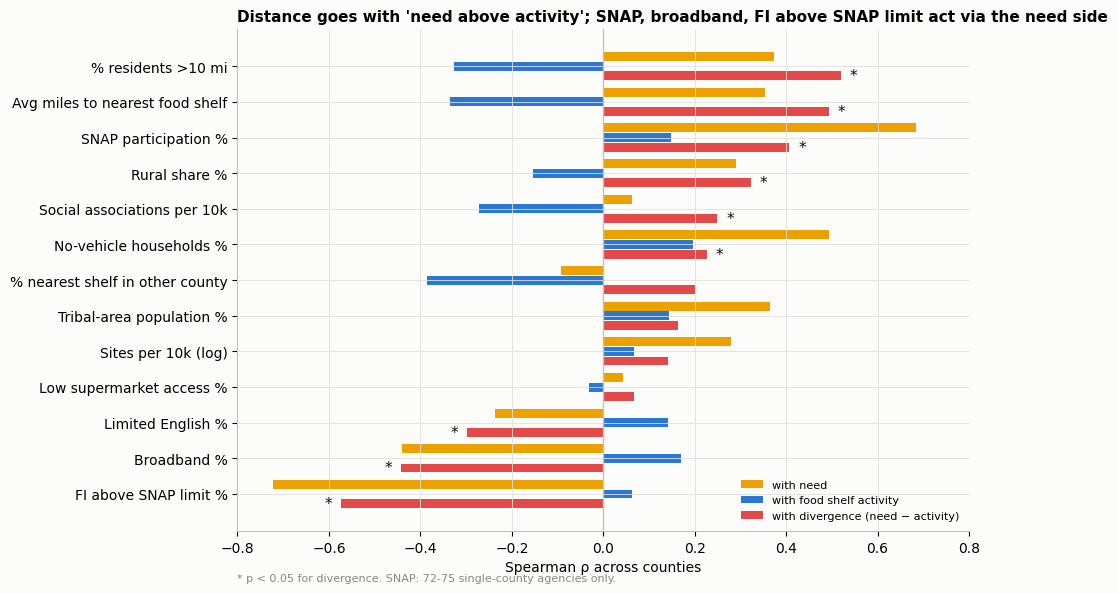

In [26]:
fig, ax = plt.subplots(figsize=(10, 6))
a = assoc.sort_values("rho with divergence")
yy = np.arange(len(a))
ax.barh(yy + 0.27, a["rho with need"], height=0.25, color="#eda100", label="with need")
ax.barh(yy, a["rho with activity"], height=0.25, color="#2a78d6", label="with food shelf activity")
ax.barh(yy - 0.27, a["rho with divergence"], height=0.25, color="#e34948", label="with divergence (need − activity)")
ax.set_yticks(yy); ax.set_yticklabels(a.index)
ax.axvline(0, color="#c3c2b7", lw=1)
for i, (r, p) in enumerate(zip(a["rho with divergence"], a["p (divergence)"])):
    if p < 0.05:
        ax.text(r + (0.02 if r > 0 else -0.02), i - 0.27, "*", ha="left" if r > 0 else "right", va="center", fontsize=11, color=INK)
ax.set_xlabel("Spearman ρ across counties"); ax.set_xlim(-0.8, 0.8)
ax.legend(frameon=False, loc="lower right", fontsize=8)
ax.set_title("Distance goes with 'need above activity'; SNAP, broadband, FI above SNAP limit act via the need side", loc="left", fontsize=11)
ax.text(0, -0.1, "* p < 0.05 for divergence. SNAP: 72-75 single-county agencies only.", transform=ax.transAxes, fontsize=8, color=MUTED)
plt.tight_layout()
fig.savefig(OUT / "q6_divergence_explainers.png", dpi=200, bbox_inches="tight"); plt.show()

### 13b. Top-divergence counties vs. the rest

Medians of each characteristic for the headline top-15 potentially underserved, the top-15 activity-above-need, and the rest; Mann-Whitney test (underserved vs rest).

In [27]:
grp = pd.Series("middle", index=E.index)
grp[E["div_combined"].nlargest(TOP_N).index] = "need above activity"
grp[E["div_combined"].nsmallest(TOP_N).index] = "activity above need"
E["group"] = grp
gt = E.groupby("group")[list(EXPL)].median().T.rename(index=EXPL)[["need above activity", "middle", "activity above need"]]
gt["p (under vs rest)"] = [stats.mannwhitneyu(E.loc[grp == "need above activity", c].dropna(), E.loc[grp != "need above activity", c].dropna()).pvalue
                           for c in EXPL]
display(gt.round(2))
print("Main food bank by group (counts):")
pd.crosstab(E["main_food_bank"], E["group"])[["need above activity", "middle", "activity above need"]]

group,need above activity,middle,activity above need,p (under vs rest)
Sites per 10k (log),0.15,0.26,-0.05,0.74
Avg miles to nearest food shelf,5.69,4.19,2.47,0.01
% residents >10 mi,19.57,9.04,0.00,0.01
% nearest shelf in other county,16.02,8.59,7.80,0.03
Rural share %,99.40,67.40,50.90,0.07
No-vehicle households %,5.46,5.10,4.67,0.10
Low supermarket access %,30.00,25.00,20.03,0.25
Tribal-area population %,0.00,0.00,0.00,0.31
Broadband %,85.92,87.43,90.51,0.01
Limited English %,0.30,0.60,1.10,0.17


Main food bank by group (counts):


group,need above activity,middle,activity above need
main_food_bank,,,
Channel One Regional Food Bank,0,7,6
North Country Food Bank,6,14,1
Second Harvest Heartland,7,25,7
Second Harvest Northland,2,9,0
The Food Group,0,1,1


### 13c. A small regression

Combined divergence on a few standardized characteristics (one per idea), robust (HC3) standard errors. Coefficients = change in divergence (percentile points) per 1 SD of the characteristic, holding the others fixed. VIF checks the predictors aren't measuring the same thing (VIF > 5 would be a warning). Associations, not causes.

In [28]:
PRED = ["log_sites_per_10k", "pct_over_10mi", "pct_nearest_other_county", "no_vehicle_rate", "pct_rural_2020",
        "pct_pop_tribal_area_approx", "chr_pct_broadband"]
R = E[["div_combined", "div_visits", "div_pounds", "div_individuals", "main_food_bank"] + PRED].dropna().copy()
for v in PRED:
    R[v] = (R[v] - R[v].mean()) / R[v].std()
X = R[PRED].assign(const=1.0)
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(len(PRED))], index=[EXPL[p] for p in PRED]).round(2)
print("VIF:", vif.to_dict())
form = " + ".join(PRED)
models = {}
for dv in ["div_combined", "div_visits", "div_pounds", "div_individuals"]:
    models[dv] = smf.ols(f"{dv} ~ {form}", data=R).fit(cov_type="HC3")
m0 = models["div_combined"]
coef = pd.DataFrame({"coef": m0.params, "95% low": m0.conf_int()[0], "95% high": m0.conf_int()[1], "p": m0.pvalues}).drop("Intercept")
coef.index = [EXPL[i] for i in coef.index]
print(f"n = {int(m0.nobs)} | R² = {m0.rsquared:.2f} | adj R² = {m0.rsquared_adj:.2f}")
print("R² per metric:", {NICE[k.replace('div_', '')]: round(v.rsquared, 2) for k, v in models.items()})
mfb = smf.ols(f"div_combined ~ {form} + C(main_food_bank)", data=R).fit(cov_type="HC3")
print(f"Adding main food bank: R² {m0.rsquared:.2f} -> {mfb.rsquared:.2f}")
display(mfb.params.filter(like="food_bank").round(1).to_frame("coef vs Channel One").assign(p=mfb.pvalues.filter(like="food_bank").round(3)))
coef.round(2)

VIF: {'Sites per 10k (log)': 2.2, '% residents >10 mi': 1.45, '% nearest shelf in other county': 1.46, 'No-vehicle households %': 1.78, 'Rural share %': 4.21, 'Tribal-area population %': 1.23, 'Broadband %': 2.54}
n = 86 | R² = 0.43 | adj R² = 0.38
R² per metric: {'Combined': 0.43, 'Visits': 0.39, 'Pounds': 0.36, 'Individuals': 0.44}
Adding main food bank: R² 0.43 -> 0.57


,coef vs Channel One,p
C(main_food_bank)[T.North Country Food Bank],29.1,0.014
C(main_food_bank)[T.Second Harvest Heartland],12.3,0.289
C(main_food_bank)[T.Second Harvest Northland],34.6,0.005
C(main_food_bank)[T.The Food Group],-54.7,0.205


,coef,95% low,95% high,p
Sites per 10k (log),-2.70,-11.12,5.72,0.53
% residents >10 mi,12.32,4.47,20.18,0.00
% nearest shelf in other county,8.70,1.28,16.12,0.02
No-vehicle households %,8.31,-0.01,16.63,0.05
Rural share %,0.88,-12.52,14.27,0.90
Tribal-area population %,1.05,-27.58,29.68,0.94
Broadband %,-16.25,-25.80,-6.70,0.00


### 13d. Same question, holding need fixed

Divergence mixes need and activity, so a characteristic that simply tracks hardship (e.g. broadband, FI above the SNAP limit) can look "explanatory" through the need side. A cleaner check: model **activity percentile** with **need percentile as a control** plus the same characteristics. A negative coefficient = *less* activity than counties with the same need, i.e. a real barrier between need and demand.

In [29]:
R2 = E[["dem_pctile_combined", "need_pctile"] + PRED].dropna().copy()
for v in PRED:
    R2[v] = (R2[v] - R2[v].mean()) / R2[v].std()
m_act = smf.ols(f"dem_pctile_combined ~ need_pctile + {form}", data=R2).fit(cov_type="HC3")
act_coef = pd.DataFrame({"coef": m_act.params, "95% low": m_act.conf_int()[0], "95% high": m_act.conf_int()[1], "p": m_act.pvalues}).drop("Intercept")
act_coef.index = [EXPL.get(i, "Need percentile") for i in act_coef.index]
print(f"Activity model: n = {int(m_act.nobs)} | R² = {m_act.rsquared:.2f}")
act_coef.round(2)

Activity model: n = 86 | R² = 0.33


,coef,95% low,95% high,p
Need percentile,0.16,-0.10,0.43,0.24
Sites per 10k (log),4.22,-3.23,11.66,0.27
% residents >10 mi,-6.96,-14.10,0.19,0.06
% nearest shelf in other county,-8.67,-15.28,-2.05,0.01
No-vehicle households %,3.09,-5.54,11.71,0.48
Rural share %,1.58,-9.30,12.45,0.78
Tribal-area population %,2.70,-2.06,7.46,0.27
Broadband %,10.67,2.33,19.00,0.01


### 13e. New ACS characteristics: barriers, not hardship

Four new ACS measures describe whether need can **turn into** a food shelf visit (awareness, eligibility fear, isolation, other programs), so, by Rule 2 (section 3), they stay **out** of the need index and are tested here as **explanations** of divergence:

| Characteristic | Idea |
|---|---|
| **SNAP gap**: % of poverty households not getting SNAP (B22003) | eligible but unreached households: awareness, stigma, paperwork. If the same barriers keep people from food shelves, a bigger SNAP gap → more divergence. |
| % foreign-born (B05002) | immigrant fear (public charge), language |
| % of people 65+ living alone (B09020) | isolation, transport |
| % American Indian / Alaska Native alone (B03002) | tribal food programs (FDPIR) and tribal food shelves may substitute |

3-window averages (2018–22 … 2020–24). Same table as section 13 (ρ with need, activity, divergence), then each one added to the section 13c regression (HC3) and to the section 13d activity model (need held fixed). With 4 characteristics × 2 models = 8 added-variable tests, we also report a Benjamini–Hochberg FDR q-value.

In [30]:
from statsmodels.stats.multitest import multipletests
ACS_EXPL = {"pct_poverty_hh_no_snap": "SNAP gap: poverty hh without SNAP %", "pct_foreign_born": "Foreign-born %",
            "pct_65plus_living_alone": "65+ living alone %", "pct_aian_alone": "American Indian / Alaska Native %"}
acs_avg = fac_y.groupby("fips")[list(ACS_EXPL)].mean()
EA = E.join(acs_avg)
rows = []
for c, lab_ in ACS_EXPL.items():
    r_div, p_div = stats.spearmanr(EA[c], EA["div_combined"])
    rows.append({"characteristic": lab_, "n": int(EA[c].notna().sum()),
                 "rho with need": EA[c].corr(EA["need_pctile"], method="spearman"),
                 "rho with activity": EA[c].corr(EA["dem_pctile_combined"], method="spearman"),
                 "rho with divergence": r_div, "p (divergence)": p_div,
                 **{f"rho div_{m}": EA[c].corr(EA[f"div_{m}"], method="spearman") for m in METRICS}})
assoc_acs = pd.DataFrame(rows).set_index("characteristic")
assoc_acs["q (FDR, 4 tests)"] = multipletests(assoc_acs["p (divergence)"], method="fdr_bh")[1]
display(assoc_acs.round(3))

# Added one at a time (and all four together) to the 13c divergence model and the 13d activity model
RA = EA[["div_combined", "dem_pctile_combined", "need_pctile"] + PRED + list(ACS_EXPL)].dropna().copy()
for v in PRED + list(ACS_EXPL):
    RA[v] = (RA[v] - RA[v].mean()) / RA[v].std()
add_rows = []
for dv, base_f in [("div_combined", f"div_combined ~ {form}"), ("dem_pctile_combined", f"dem_pctile_combined ~ need_pctile + {form}")]:
    b = smf.ols(base_f, data=RA).fit(cov_type="HC3")
    for c in list(ACS_EXPL) + ["all four"]:
        add = " + ".join(ACS_EXPL) if c == "all four" else c
        m1 = smf.ols(f"{base_f} + {add}", data=RA).fit(cov_type="HC3")
        if c == "all four":
            p = float(m1.wald_test(" , ".join(f"{a} = 0" for a in ACS_EXPL), scalar=True).pvalue); coef_ = np.nan
        else:
            p, coef_ = m1.pvalues[c], m1.params[c]
        add_rows.append({"model": "divergence (13c)" if dv == "div_combined" else "activity | need (13d)",
                         "added": ACS_EXPL.get(c, c), "coef per SD": coef_, "p (HC3)": p,
                         "adj R² base": b.rsquared_adj, "adj R² +added": m1.rsquared_adj, "Δ adj R²": m1.rsquared_adj - b.rsquared_adj})
added = pd.DataFrame(add_rows)
one_at_a_time = added["added"] != "all four"
added.loc[one_at_a_time, "q (FDR, 8 tests)"] = multipletests(added.loc[one_at_a_time, "p (HC3)"], method="fdr_bh")[1]
print(f"n = {len(RA)} counties (86 with a food shelf, minus missing predictors)")
added.round(3)

,n,rho with need,rho with activity,rho with divergence,p (divergence),rho div_visits,rho div_pounds,rho div_individuals,"q (FDR, 4 tests)"
characteristic,,,,,,,,,
SNAP gap: poverty hh without SNAP %,86,-0.458,-0.214,-0.184,0.090,-0.214,-0.179,-0.165,0.120
Foreign-born %,86,-0.286,0.203,-0.394,0.000,-0.334,-0.292,-0.441,0.001
65+ living alone %,86,0.171,0.021,0.096,0.378,0.099,0.091,0.105,0.378
American Indian / Alaska Native %,86,0.492,0.119,0.236,0.028,0.257,0.249,0.252,0.057


n = 86 counties (86 with a food shelf, minus missing predictors)


,model,added,coef per SD,p (HC3),adj R² base,adj R² +added,Δ adj R²,"q (FDR, 8 tests)"
0,divergence (13c),SNAP gap: poverty hh without SNAP %,-1.177,0.788,0.376,0.369,-0.007,0.788
1,divergence (13c),Foreign-born %,-4.378,0.641,0.376,0.377,0.001,0.788
2,divergence (13c),65+ living alone %,-5.268,0.184,0.376,0.383,0.006,0.788
3,divergence (13c),American Indian / Alaska Native %,8.169,0.269,0.376,0.376,-0.001,0.788
4,divergence (13c),all four,NaN,0.229,0.376,0.379,0.002,NaN
5,activity | need (13d),SNAP gap: poverty hh without SNAP %,-3.651,0.355,0.266,0.267,0.002,0.788
6,activity | need (13d),Foreign-born %,4.570,0.480,0.266,0.273,0.008,0.788
7,activity | need (13d),65+ living alone %,1.275,0.691,0.266,0.257,-0.008,0.788
8,activity | need (13d),American Indian / Alaska Native %,1.607,0.715,0.266,0.256,-0.009,0.788
9,activity | need (13d),all four,NaN,0.717,0.266,0.260,-0.006,NaN


**Result: none of the four adds to the explanation.**
- **Foreign-born share** has the strongest raw link (ρ = −0.39 with divergence, p < 0.001; survives FDR over these 4 tests). But it works through **both** sides: foreign-born counties have *lower* need (ρ = −0.29) and *more* activity (+0.20) — most are metro and regional-centre counties (Ramsey, Hennepin, Watonwan, Mower, Olmsted, Scott, Dakota) with short distances to a food shelf. The clear exception is **Nobles** (Worthington; 21% foreign-born, the highest in the state), which is a top "need above activity" county (+76) — a case worth a closer look, but one county is not a pattern. Once distance, cross-county use, sites and rurality are in the model it adds nothing (p = 0.64, Δ adj R² ≈ 0). So there is **no sign that immigrant fear suppresses food shelf use at county level**; county data can't see it, if it exists.
- **American Indian share** (ρ = +0.24, p = 0.03; q ≈ 0.06) also runs through the **need** side (ρ = +0.49 with need, +0.12 with activity): AIAN counties are poorer, not under-using shelves. In the models: p = 0.27 and 0.72.
- **SNAP gap** (poverty households without SNAP): ρ = −0.18 (p = 0.09), again via need (ρ = −0.46: poorer counties have *more* of their poor households on SNAP). Adds nothing (p = 0.79 / 0.36).
- **Seniors living alone:** ρ = +0.10, p = 0.38. Nothing.
- **All four together** do not improve either model (robust Wald p = 0.23 for divergence, 0.72 for activity-given-need; adjusted R² changes by < 0.01). No added-variable test passes FDR (all q = 0.79).

**So the section 13 conclusion holds:** divergence follows **physical access and the food shelf network** (distance, cross-county nearest shelf), not awareness/eligibility proxies that are visible in county-level ACS data.

### 13f. SNAP retailer access (USDA FNS retailer locator, `06c_extra_factors.ipynb`)

Does it matter whether a county has stores that take SNAP, and how far people live from a full-service one? Five characteristics (all **access**, so they stay out of the need index by Rule 2):

| Characteristic | Idea |
|---|---|
| SNAP retailers per 10k (2022–24 avg) | where SNAP can be spent (all store types) |
| Full-service SNAP stores per 10k (2022–24 avg) | supermarkets, super stores, large grocery |
| Miles to the nearest full-service SNAP store (2024, population-weighted) | grocery distance; if far, SNAP dollars go less far and food shelves may matter more, *or* everything is far |
| % residents > 10 miles from one (2024) | same, as a share |
| Net change in SNAP retailers per 10k, 2022→2025 | store closures |

Same steps as 13e: Spearman with need, activity, divergence **and meal-gap coverage 2024** (section 10b); then each one added to the 13c divergence model, the 13d activity-given-need model, and a coverage model (log coverage 2024 on the same 7 characteristics), with HC3 standard errors, adjusted R² and FDR over the 15 added-variable tests.

In [31]:
SNAP_EXPL = {"snap_retailers_per_10k_2224": "SNAP retailers per 10k", "snap_full_service_per_10k_2224": "Full-service SNAP stores per 10k",
             "snap_full_mean_dist_mi_2024": "Miles to nearest full-service SNAP store", "snap_full_pct_over_10mi_2024": "% >10 mi from full-service SNAP store",
             "snap_net_change_per_10k_2022_2025": "Net change SNAP retailers per 10k 2022-25"}
snap_avg = ex_y[ex_y["year"].between(2022, 2024)].groupby("fips")[["snap_retailers_per_10k", "snap_full_service_per_10k"]].mean().add_suffix("_2224")
ES = E.join(snap_avg).join(ex_s[["snap_full_mean_dist_mi_2024", "snap_full_pct_over_10mi_2024", "snap_net_change_per_10k_2022_2025"]])
ES = ES.join(cov[["coverage_2024"]])
ES["log_coverage_2024"] = np.log(ES["coverage_2024"])
rows = []
for c, lab_ in SNAP_EXPL.items():
    r_div, p_div = stats.spearmanr(ES[c], ES["div_combined"])
    ok = ES["coverage_2024"].notna()
    r_cov, p_cov = stats.spearmanr(ES.loc[ok, c], ES.loc[ok, "coverage_2024"])
    rows.append({"characteristic": lab_, "rho with need": ES[c].corr(ES["need_pctile"], method="spearman"),
                 "rho with activity": ES[c].corr(ES["dem_pctile_combined"], method="spearman"),
                 "rho with divergence": r_div, "p (divergence)": p_div, "rho with coverage 2024": r_cov, "p (coverage)": p_cov,
                 "rho with Q1 food shelf distance": ES[c].corr(ES["mean_dist_mi"], method="spearman")})
assoc_snap = pd.DataFrame(rows).set_index("characteristic")
assoc_snap["q div (FDR, 5)"] = multipletests(assoc_snap["p (divergence)"], method="fdr_bh")[1]
assoc_snap["q cov (FDR, 5)"] = multipletests(assoc_snap["p (coverage)"], method="fdr_bh")[1]
display(assoc_snap.round(3))

RS = ES[["div_combined", "dem_pctile_combined", "need_pctile", "log_coverage_2024"] + PRED + list(SNAP_EXPL)].dropna().copy()
for v in PRED + list(SNAP_EXPL):
    RS[v] = (RS[v] - RS[v].mean()) / RS[v].std()
add_rows = []
for model, base_f in [("divergence (13c)", f"div_combined ~ {form}"), ("activity | need (13d)", f"dem_pctile_combined ~ need_pctile + {form}"),
                      ("log coverage 2024", f"log_coverage_2024 ~ {form}")]:
    b = smf.ols(base_f, data=RS).fit(cov_type="HC3")
    for c in list(SNAP_EXPL) + ["all five"]:
        add = " + ".join(SNAP_EXPL) if c == "all five" else c
        m1 = smf.ols(f"{base_f} + {add}", data=RS).fit(cov_type="HC3")
        if c == "all five":
            p = float(m1.wald_test(" , ".join(f"{a} = 0" for a in SNAP_EXPL), scalar=True).pvalue); coef_ = np.nan
        else:
            p, coef_ = m1.pvalues[c], m1.params[c]
        add_rows.append({"model": model, "added": SNAP_EXPL.get(c, c), "coef per SD": coef_, "p (HC3)": p,
                         "adj R² base": b.rsquared_adj, "adj R² +added": m1.rsquared_adj, "Δ adj R²": m1.rsquared_adj - b.rsquared_adj})
added_snap = pd.DataFrame(add_rows)
one_s = added_snap["added"] != "all five"
added_snap.loc[one_s, "q (FDR, 15 tests)"] = multipletests(added_snap.loc[one_s, "p (HC3)"], method="fdr_bh")[1]
print(f"n = {len(RS)} counties (with a food shelf and a 2024 coverage value)")
added_snap.round(3)

,rho with need,rho with activity,rho with divergence,p (divergence),rho with coverage 2024,p (coverage),rho with Q1 food shelf distance,"q div (FDR, 5)","q cov (FDR, 5)"
characteristic,,,,,,,,,
SNAP retailers per 10k,0.605,-0.029,0.464,0.000,-0.257,0.017,0.463,0.000,0.035
Full-service SNAP stores per 10k,0.265,0.010,0.185,0.088,-0.059,0.590,0.344,0.110,0.737
Miles to nearest full-service SNAP store,0.447,-0.220,0.498,0.000,-0.278,0.009,0.710,0.000,0.035
% >10 mi from full-service SNAP store,0.437,-0.205,0.474,0.000,-0.248,0.021,0.595,0.000,0.035
Net change SNAP retailers per 10k 2022-25,-0.234,-0.093,-0.109,0.317,-0.027,0.808,0.125,0.317,0.808


n = 86 counties (with a food shelf and a 2024 coverage value)


,model,added,coef per SD,p (HC3),adj R² base,adj R² +added,Δ adj R²,"q (FDR, 15 tests)"
0,divergence (13c),SNAP retailers per 10k,2.601,0.725,0.376,0.371,-0.006,0.917
1,divergence (13c),Full-service SNAP stores per 10k,-2.233,0.452,0.376,0.371,-0.005,0.888
2,divergence (13c),Miles to nearest full-service SNAP store,15.881,0.000,0.376,0.446,0.070,0.004
3,divergence (13c),% >10 mi from full-service SNAP store,9.906,0.039,0.376,0.406,0.029,0.197
4,divergence (13c),Net change SNAP retailers per 10k 2022-25,-0.584,0.890,0.376,0.368,-0.008,0.944
5,divergence (13c),all five,NaN,0.010,0.376,0.428,0.052,NaN
6,activity | need (13d),SNAP retailers per 10k,1.594,0.725,0.266,0.258,-0.008,0.917
7,activity | need (13d),Full-service SNAP stores per 10k,0.406,0.908,0.266,0.256,-0.010,0.944
8,activity | need (13d),Miles to nearest full-service SNAP store,-9.000,0.011,0.266,0.297,0.032,0.085
9,activity | need (13d),% >10 mi from full-service SNAP store,-6.907,0.088,0.266,0.288,0.023,0.328


In [32]:
# Does grocery distance work through the same channel as food shelf distance? Swap it in for the food shelf distance.
alt_pred = [p_ if p_ != "pct_over_10mi" else "snap_full_pct_over_10mi_2024" for p_ in PRED]
RS2 = ES[["div_combined"] + list(dict.fromkeys(PRED + alt_pred))].dropna().copy()
for v in RS2.columns[1:]:
    RS2[v] = (RS2[v] - RS2[v].mean()) / RS2[v].std()
m_food = smf.ols("div_combined ~ " + " + ".join(PRED), data=RS2).fit(cov_type="HC3")
m_groc = smf.ols("div_combined ~ " + " + ".join(alt_pred), data=RS2).fit(cov_type="HC3")
m_both = smf.ols("div_combined ~ " + " + ".join(PRED + ["snap_full_pct_over_10mi_2024"]), data=RS2).fit(cov_type="HC3")
print(f"Divergence model with % >10 mi from a FOOD SHELF: adj R² = {m_food.rsquared_adj:.3f}, coef {m_food.params['pct_over_10mi']:+.1f} (p = {m_food.pvalues['pct_over_10mi']:.3f})")
print(f"... with % >10 mi from a full-service SNAP STORE instead: adj R² = {m_groc.rsquared_adj:.3f}, coef {m_groc.params['snap_full_pct_over_10mi_2024']:+.1f} (p = {m_groc.pvalues['snap_full_pct_over_10mi_2024']:.3f})")
print(f"... with both: food shelf {m_both.params['pct_over_10mi']:+.1f} (p = {m_both.pvalues['pct_over_10mi']:.3f}), "
      f"SNAP store {m_both.params['snap_full_pct_over_10mi_2024']:+.1f} (p = {m_both.pvalues['snap_full_pct_over_10mi_2024']:.3f}); adj R² = {m_both.rsquared_adj:.3f}")
print("Spearman, % >10 mi from a food shelf vs from a full-service SNAP store:",
      round(ES["pct_over_10mi"].corr(ES["snap_full_pct_over_10mi_2024"], method="spearman"), 2))

Divergence model with % >10 mi from a FOOD SHELF: adj R² = 0.376, coef +12.3 (p = 0.002)
... with % >10 mi from a full-service SNAP STORE instead: adj R² = 0.393, coef +13.6 (p = 0.002)
... with both: food shelf +7.3 (p = 0.115), SNAP store +9.9 (p = 0.039); adj R² = 0.406
Spearman, % >10 mi from a food shelf vs from a full-service SNAP store: 0.63


**Result (13f): distance to a full-service grocery store matters; store counts and closures don't.**
- **Raw links:** counties farther from a full-service SNAP store diverge more (ρ = +0.50; % > 10 miles +0.47) and have lower meal-gap coverage (ρ = −0.28). SNAP retailers per 10k also correlate with divergence (+0.46), but through the **need** side (ρ = +0.61 with need, −0.03 with activity): poorer rural counties have many small stores per resident. Full-service stores per 10k (+0.19) and the 2022→2025 net change (−0.11) show nothing.
- **Holding the access characteristics fixed:** **miles to the nearest full-service SNAP store adds clearly to the divergence model** (+15.9 percentile points per SD, p < 0.001, **q = 0.004** over 15 tests; adjusted R² 0.38 → **0.45**). In the activity-given-need model it points the same way (−9.0 per SD, p = 0.01, q = 0.09). Store counts and closures add nothing (p ≥ 0.45). **None** of the five adds to the coverage model (all p ≥ 0.26; together p = 0.93).
- **It is general remoteness, not grocery access as such.** Grocery and food shelf distance overlap (ρ = 0.71 for average miles, 0.63 for % > 10 mi). With both in the model, grocery distance keeps p = 0.04 and food shelf distance drops to p = 0.12; each alone fits about equally (adj R² 0.39 vs 0.38). The honest reading: **people who live far from everything** (stores, food shelves) record less food shelf activity than their need suggests. Q1b found the same distance does *not* explain the Q1 mismatch gap (section 8c there), because that gap is measured against MMG only, a narrower need measure.
- **Closures:** Minnesota's SNAP retailer network grew slightly 2022→2025 (net +102 stores), and county closures are too few to explain anything.

## 14. Outside checks: hotline calls and SNAP

If "need above activity" is real, other signals of need should be present there. Two imperfect checks:
- **The Food Group hotline (`Incoming Call.xlsx`)**, 2022-2024 calls by caller county, per 10,000 residents. Calls are also *demand* and the hotline is Twin Cities-based, so expect a strong awareness/metro bias.
- **SNAP participation** (single-county agencies only): high SNAP where divergence is high would suggest need is real but met through SNAP.

In [33]:
calls = pd.read_excel(ROOT / "Data" / "Incoming Call.xlsx", usecols=["Date", "County", "PrimaryReasonForCall"])
calls = calls[calls["Date"].dt.year.between(2022, 2024)]
assert calls["Date"].max() < pd.Timestamp("2026-08-01")
name2fips = {v.lower(): k for k, v in COUNTY.items()}
def to_fips(c):
    if not isinstance(c, str):
        return None
    c = c.split("-")[0].strip().lower().replace("saint ", "st. ")
    return name2fips.get(c)
calls["fips"] = calls["County"].map(to_fips)
print(f"Calls 2022-2024: {len(calls):,} | matched to a MN county: {calls['fips'].notna().mean():.0%} | years: {calls['Date'].dt.year.value_counts().sort_index().to_dict()}")
cpc = calls.groupby("fips").size().rename("calls")
E["calls_per_10k"] = (E.index.map(cpc).fillna(0) / E["pop_pep"] * 1e4)
E["foodshelf_calls_per_10k"] = E.index.map(calls[calls["PrimaryReasonForCall"] == "Food Shelf"].groupby("fips").size()).fillna(0) / E["pop_pep"] * 1e4
chk = pd.DataFrame({c: {"rho with need": E[c].corr(E["need_pctile"], method="spearman"),
                        "rho with activity": E[c].corr(E["dem_pctile_combined"], method="spearman"),
                        "rho with divergence": E[c].corr(E["div_combined"], method="spearman"),
                        "median: need above activity": E.loc[E["group"] == "need above activity", c].median(),
                        "median: rest": E.loc[E["group"] != "need above activity", c].median()}
                    for c in ["calls_per_10k", "foodshelf_calls_per_10k", "snap_rate"]}).T
chk.round(2)

Calls 2022-2024: 30,075 | matched to a MN county: 58% | years: {2022: 41, 2023: 15434, 2024: 14600}


,rho with need,rho with activity,rho with divergence,median: need above activity,median: rest
calls_per_10k,0.08,0.22,-0.11,8.94,8.73
foodshelf_calls_per_10k,0.10,0.18,-0.06,1.63,1.88
snap_rate,0.68,0.15,0.41,8.41,6.80


## 15. What would prove this measure wrong?

Our claim is that in high-divergence counties need is **larger than activity shows**. It would be undermined if:
1. **Residents are served elsewhere**: client-ZIP data showed residents of top-divergence counties using shelves in neighbouring counties at rates that close the gap (the reallocation in section 11 is only a nearest-shelf approximation).
2. **Need is met by other programs**: SNAP participation, tribal food programs (FDPIR) or school meals were clearly higher in top-divergence counties than elsewhere.
3. **The need side is noise**: the top list changed when Map the Meal Gap or ACS estimates are revised, or was mostly small counties with wide margins of error.
4. **No other signal of hardship appears there**: hotline calls, SNAP applications or 211 requests from these counties were no higher than elsewhere *once awareness is accounted for*.
5. **Missing reports**: food shelves in those counties were under-reporting (Q1's data-quality category).

Sections 11, 12 and 14 test parts of (1)-(4) with the data we have.

## 16. Final county table and labels

**Category label** (combined divergence):
- `potentially underserved (robust)`: headline top 15 and top 15 in ≥ 75% of versions;
- `potentially underserved (method-dependent)`: headline top 15, less persistent;
- `activity above need (robust)` / `(method-dependent)`: same for the bottom 15;
- `aligned`: everyone else; `no food shelf in data` (Wilkin).

In [34]:
final = need.join(dem[PER1K + ["n_years_used", "any_incomplete"]]).join(
    scored[[c for c in scored.columns if c.startswith(("dz_", "div_", "dem_pctile_")) or c == "need_pctile"]]).join(stab)
final["county"] = final.index.map(COUNTY)
final["rank_underserved"] = final["div_combined"].rank(ascending=False, method="min")
final["flag_small_county_lt10k"] = final["pop_pep"] < 10_000
final["flag_data_quality_q1"] = final.index.isin(DQ)
final["pct_nearest_other_county"] = final.index.map(q1.set_index("fips")["pct_nearest_other_county"])
final["flag_cross_county_gt25"] = final["pct_nearest_other_county"] > 25
# Count version: annual activity expected if the county had the MEDIAN county's activity per person in need.
# (Median, not statewide total: Hennepin/Ramsey hubs would otherwise set the bar and make almost every county look short.)
for m in METRICS:
    tot = final[f"{m}_per_1k"] * final["pop_pep"] / 1000
    rate = (tot / final["need_persons"]).median()
    final[f"{m}_expected_from_need"] = final["need_persons"] * rate
    final[f"{m}_gap_count"] = final[f"{m}_expected_from_need"] - tot.fillna(0)
top_idx, bot_idx = final["div_combined"].nlargest(TOP_N).index, final["div_combined"].nsmallest(TOP_N).index
cat = pd.Series("aligned", index=final.index)
cat[top_idx] = np.where(final.loc[top_idx, "share_top15_under"] >= 0.75, "potentially underserved (robust)", "potentially underserved (method-dependent)")
cat[bot_idx] = np.where(final.loc[bot_idx, "share_top15_over"] >= 0.75, "activity above need (robust)", "activity above need (method-dependent)")
cat[final["div_combined"].isna()] = "no food shelf in data"
final["category"] = cat
print("Largest shortfalls in COUNT terms (individuals per year below the median county's individuals per person in need):")
display(final.sort_values("individuals_gap_count", ascending=False)[["county", "need_persons", "individuals_gap_count", "visits_gap_count", "div_combined"]].head(10).round(0))

# Short per-county note on what the three metrics say
def metric_note(r):
    if pd.isna(r["div_combined"]):
        return "no food shelf in data: all need unseen locally"
    hi = [NICE[m] for m in METRICS if r[f"div_{m}"] >= 40]
    lo = [NICE[m] for m in METRICS if r[f"div_{m}"] <= -40]
    if len(hi) == 3: return "all three metrics well below need"
    if len(lo) == 3: return "all three metrics well above need"
    parts = ([f"{'/'.join(hi)} well below need"] if hi else []) + ([f"{'/'.join(lo)} well above need"] if lo else [])
    return "; ".join(parts) if parts else "metrics roughly in line with need"
final["metric_note"] = final.apply(metric_note, axis=1)

# Section 10b meal-gap coverage (2024 headline, 2023 check). Added at the end so earlier columns keep their order.
COV_COLS = ["meal_gap_meals_2024", "foodshelf_meals_2024", "meal_gap_coverage_2024", "meal_gap_coverage_2023",
            "indiv_per_fi_person_2024", "coverage_incomplete_2024"]
final = final.join(cov[["meal_gap_meals_2024", "foodshelf_meals_2024", "coverage_2024", "coverage_2023", "indiv_per_fi_2024", "incomplete_2024"]]
                   .rename(columns={"coverage_2024": "meal_gap_coverage_2024", "coverage_2023": "meal_gap_coverage_2023",
                                    "indiv_per_fi_2024": "indiv_per_fi_person_2024", "incomplete_2024": "coverage_incomplete_2024"}))
final["coverage_incomplete_2024"] = final["coverage_incomplete_2024"].astype("boolean")

out_cols = (["county", "pop_pep", "fi_rate", "need_ew", "need_pca", "need_mmg", "need_rate_adj", "need_persons", "need_pctile"]
            + PER1K + ["n_years_used", "any_incomplete"] + [f"dz_{m}" for m in METRICS + ["combined"]]
            + [f"dem_pctile_{m}" for m in METRICS + ["combined"]] + [f"div_{m}" for m in METRICS + ["combined"]]
            + ["div_z_combined", "div_resid_combined"] + (["div_combined_resident"] if realloc_ok else [])
            + ["rank_underserved", "share_top15_under", "share_top15_over"]
            + [f"{m}_gap_count" for m in METRICS]
            + ["pct_nearest_other_county", "flag_cross_county_gt25", "flag_small_county_lt10k", "flag_data_quality_q1", "category", "metric_note"]
            + COV_COLS)   # section 10b, appended at the end (columns added only)
save = final[out_cols].reset_index().rename(columns={"index": "fips"}).sort_values("rank_underserved", na_position="last")
save.insert(1, "headline_need_index", V3[HEADLINE])
assert len(save) == 87 and save["fips"].is_unique
save.round(4).to_csv(PROCESSED / "q6_county_need_divergence.csv", index=False)
print("Saved q6_county_need_divergence.csv", save.shape)
save["category"].value_counts()

Largest shortfalls in COUNT terms (individuals per year below the median county's individuals per person in need):


,county,need_persons,individuals_gap_count,visits_gap_count,div_combined
fips,,,,,
27139,Scott,11603.0,28637.0,13307.0,-5.0
27103,Nicollet,3528.0,13577.0,5635.0,28.0
27009,Benton,4571.0,12803.0,4662.0,43.0
27111,Otter Tail,6799.0,12441.0,4685.0,30.0
27041,Douglas,4037.0,10416.0,4321.0,8.0
27017,Carlton,4502.0,8836.0,2329.0,47.0
27097,Morrison,4035.0,8432.0,2762.0,40.0
27015,Brown,2572.0,8217.0,2915.0,9.0
27153,Todd,3061.0,7906.0,3305.0,59.0


Saved q6_county_need_divergence.csv (87, 49)


category
aligned                                       56
potentially underserved (robust)              14
activity above need (robust)                  14
potentially underserved (method-dependent)     1
activity above need (method-dependent)         1
no food shelf in data                          1
Name: count, dtype: int64

In [35]:
# Columns added after the first version (06c datasets): appended at the end; every existing column is checked unchanged.
q6_path = PROCESSED / "q6_county_need_divergence.csv"
saved = pd.read_csv(q6_path, dtype={"fips": str})
EXTRA = pd.DataFrame(index=saved["fips"])
EXTRA["div_combined_with_col_gap"] = d_add
EXTRA["need_pctile_with_col_gap"] = pct(col_div["(a) add affordability gap (9 components)"][0].reindex(scored.index))
EXTRA["col_affordability_gap_fam3"] = ex_s["col_affordability_gap_fam3"]
EXTRA["wic_infants_children_per_100_under5_2022"] = wic22["wic_infants_children_per_100_under5"]
EXTRA["snap_retailers_per_10k_2224"] = snap_avg["snap_retailers_per_10k_2224"]
EXTRA["snap_full_mean_dist_mi_2024"] = ex_s["snap_full_mean_dist_mi_2024"]
EXTRA["snap_full_pct_over_10mi_2024"] = ex_s["snap_full_pct_over_10mi_2024"]
EXTRA["snap_net_change_per_10k_2022_2025"] = ex_s["snap_net_change_per_10k_2022_2025"]
base_cols = [c for c in saved.columns if c not in EXTRA.columns]
out = saved[base_cols].merge(EXTRA.reset_index(), on="fips", how="left", validate="one_to_one")
chk = pd.read_csv(q6_path, dtype={"fips": str})
assert out[base_cols].astype(str).equals(chk[base_cols].astype(str)), "existing Q6 columns changed"
out.round(4).to_csv(q6_path, index=False)
print("q6_county_need_divergence.csv:", len(base_cols), "existing columns unchanged +", EXTRA.shape[1], "new columns ->", out.shape)

q6_county_need_divergence.csv: 49 existing columns unchanged + 8 new columns -> (87, 57)


## 17. Map

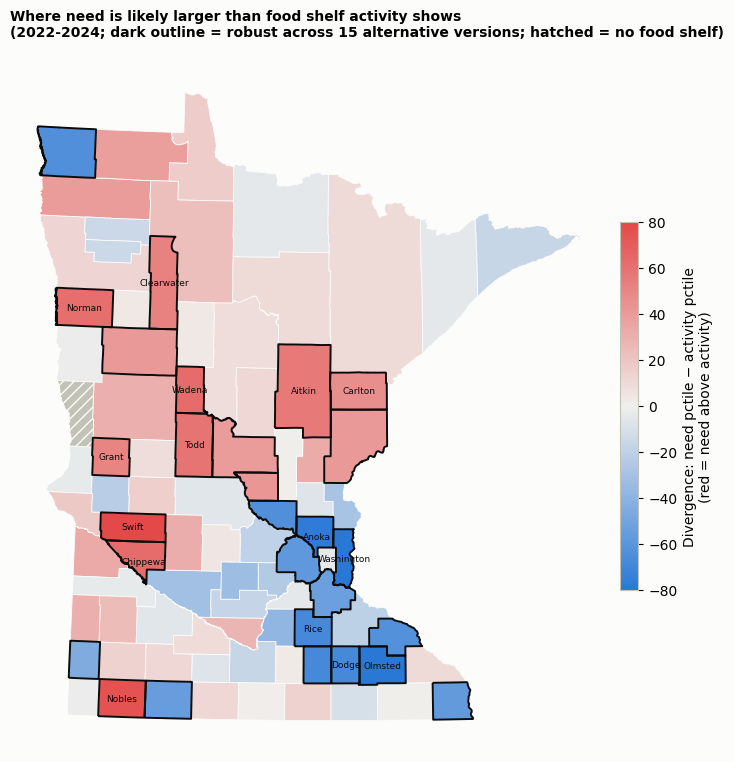

In [36]:
try:
    import geopandas as gpd
    shp = LOCAL / "cb_2023_us_county_500k.zip"
    if not shp.exists():
        shp.write_bytes(requests.get("https://www2.census.gov/geo/tiger/GENZ2023/shp/cb_2023_us_county_500k.zip", timeout=120).content)
    g = gpd.read_file(shp)
    g = g[g["STATEFP"] == "27"].assign(fips=lambda d: d["GEOID"]).to_crs(26915)
    g = g.merge(final[["div_combined", "category"]], left_on="fips", right_index=True, how="left")
    fig, ax = plt.subplots(figsize=(7.5, 8.5))
    g.plot(column="div_combined", cmap=DIV_CMAP, vmin=-80, vmax=80, edgecolor="#fcfcfb", linewidth=0.6, ax=ax,
           missing_kwds={"color": "#c3c2b7", "hatch": "///", "edgecolor": "#fcfcfb"})
    rob = g[g["category"].str.contains("robust", na=False)]
    rob.boundary.plot(ax=ax, color=INK, linewidth=1.4)
    for _, r in g[g["fips"].isin(list(top_idx[:10]) + list(bot_idx[:5]))].iterrows():
        p = r.geometry.representative_point()
        ax.text(p.x, p.y, r["NAME"], fontsize=6.5, ha="center", va="center", color=INK)
    sm = plt.cm.ScalarMappable(cmap=DIV_CMAP, norm=plt.Normalize(-80, 80))
    cb = fig.colorbar(sm, ax=ax, shrink=0.45, pad=0.01)
    cb.set_label("Divergence: need pctile − activity pctile\n(red = need above activity)")
    ax.set_axis_off()
    ax.set_title("Where need is likely larger than food shelf activity shows\n(2022-2024; dark outline = robust across 15 alternative versions; hatched = no food shelf)",
                 loc="left", fontsize=10)
    plt.tight_layout()
    fig.savefig(OUT / "q6_divergence_map.png", dpi=200, bbox_inches="tight"); plt.show()
except Exception as e:
    print("Map skipped:", repr(e))

## 18. Slide-ready summary

,County,Population,Need pctile,Activity pctile,Div. visits,Div. pounds,Div. individuals,Robust (share of versions),% nearest shelf other county,Flags
1,Swift,9700,94,12,77,86,77,100%,24,small
2,Nobles,22000,92,16,79,80,53,94%,16,
3,Wadena,14300,90,27,63,67,58,100%,15,
4,Chippewa,12300,85,22,55,71,52,100%,35,
5,Norman,6300,66,5,63,65,62,100%,8,small
6,Todd,25800,73,14,62,52,58,100%,22,
7,Aitkin,16200,98,42,48,69,58,100%,16,
8,Clearwater,8600,99,47,47,45,52,94%,7,small
9,Grant,6100,71,20,51,36,57,100%,0,"small, data quality"
10,Carlton,36700,81,35,43,55,51,100%,5,


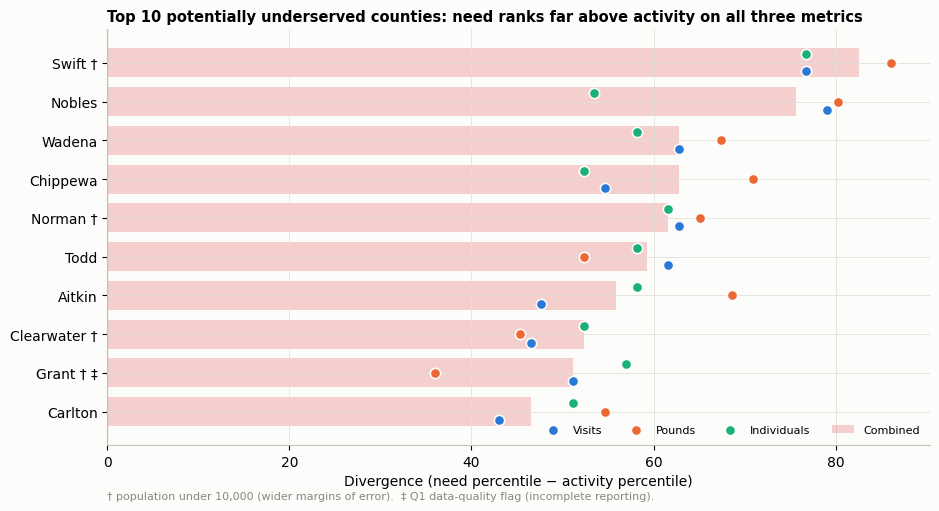

KEY SENTENCES
1. Need and food shelf activity per resident barely line up (Spearman ρ = 0.11), so a county's hardship says little about how much food shelf use it records.
2. 14 of the top-15 'need above activity' counties stay in the top 15 in at least 75% of 16 versions (headline + 15 alternatives), led by Swift, Nobles, Wadena, Chippewa, Norman: rural counties whose need ranks high but whose food shelves record little.
3. Divergence follows physical access more than hardship: counties with more residents >10 miles from a food shelf diverge more (ρ = +0.52; +12 points per SD in the regression), as do counties whose nearest food shelf is across the county line (+9 points per SD).


In [37]:
t10 = final.sort_values("div_combined", ascending=False).head(10)
slide = pd.DataFrame({
    "County": t10["county"], "Population": t10["pop_pep"].round(-2).astype(int),
    "Need pctile": t10["need_pctile"].round(0).astype(int), "Activity pctile": t10["dem_pctile_combined"].round(0).astype(int),
    "Div. visits": t10["div_visits"].round(0).astype(int), "Div. pounds": t10["div_pounds"].round(0).astype(int),
    "Div. individuals": t10["div_individuals"].round(0).astype(int),
    "Robust (share of versions)": (t10["share_top15_under"] * 100).round(0).astype(int).astype(str) + "%",
    "% nearest shelf other county": t10["pct_nearest_other_county"].round(0).astype(int),
    "Flags": [", ".join(x for x, f in [("small", s), ("data quality", d)] if f) for s, d in zip(t10["flag_small_county_lt10k"], t10["flag_data_quality_q1"])]}).reset_index(drop=True)
slide.index += 1
slide.to_csv(OUT / "q6_top10_potentially_underserved.csv")
display(slide)

fig, ax = plt.subplots(figsize=(9.5, 5.2))
order = t10.index[::-1]
for k, m in enumerate(METRICS):
    ax.scatter(final.loc[order, f"div_{m}"], np.arange(len(order)) + (k - 1) * 0.22, color=COLOR[m], s=55, label=NICE[m],
               edgecolor="#fcfcfb", linewidth=1.2, zorder=3)
ax.barh(np.arange(len(order)), final.loc[order, "div_combined"], color=UNDER, alpha=0.25, height=0.75, label="Combined")
ax.set_yticks(np.arange(len(order)))
ax.set_yticklabels([f"{COUNTY[f]}{' †' if final.loc[f, 'flag_small_county_lt10k'] else ''}{' ‡' if final.loc[f, 'flag_data_quality_q1'] else ''}" for f in order])
ax.axvline(0, color="#c3c2b7", lw=1)
ax.set_xlabel("Divergence (need percentile − activity percentile)")
ax.set_title("Top 10 potentially underserved counties: need ranks far above activity on all three metrics", loc="left", fontsize=10.5)
ax.legend(frameon=False, ncol=4, loc="lower right", fontsize=8)
ax.text(0, -0.13, "† population under 10,000 (wider margins of error).  ‡ Q1 data-quality flag (incomplete reporting).", transform=ax.transAxes, fontsize=8, color=MUTED)
plt.tight_layout()
fig.savefig(OUT / "q6_top10_by_metric.png", dpi=200, bbox_inches="tight"); plt.show()

print("KEY SENTENCES")
print(f"1. Need and food shelf activity per resident barely line up (Spearman ρ = {scored[HEADLINE].corr(scored['dz_combined'], method='spearman'):.2f}), "
      f"so a county's hardship says little about how much food shelf use it records.")
print(f"2. {len(robust_under)} of the top-15 'need above activity' counties stay in the top 15 in at least 75% of {V.shape[1]} versions (headline + {V.shape[1] - 1} alternatives), led by "
      f"{', '.join(final.loc[robust_under].sort_values('div_combined', ascending=False)['county'].head(5))}: rural counties whose need ranks high but whose food shelves record little.")
print(f"3. Divergence follows physical access more than hardship: counties with more residents >10 miles from a food shelf diverge more "
      f"(ρ = {assoc.loc['% residents >10 mi', 'rho with divergence']:+.2f}; +{coef.loc['% residents >10 mi', 'coef']:.0f} points per SD in the regression), "
      f"as do counties whose nearest food shelf is across the county line (+{coef.loc['% nearest shelf in other county', 'coef']:.0f} points per SD).")